[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QVerifier_ProvableRobustness_Barooti2021.ipynb)

# Provable adversarial robustness in the quantum model: Barooti, Gluch and Urbanke (2021), checked step by step

**Paper.** Khashayar Barooti, Grzegorz Gluch and Ruediger Urbanke, *Provable Adversarial Robustness in the Quantum Model*,
arXiv:2112.09625 (December 2021), [https://arxiv.org/abs/2112.09625](https://arxiv.org/abs/2112.09625). Authors: EPFL, Lausanne.

**What kind of paper this is.** A theory paper. It has **no experiment, no dataset and no table of numbers**. Its claims are lemmas and theorems about
a protocol between a verifier `V` and a (possibly dishonest) prover `P`, in which `P` hands `V` *quantum samples* `|psi_D> = sum_x sqrt(D(x)) |x>` of
the data distribution `D`. If `V` accepts, the classical samples it extracts are guaranteed to come from a distribution that is Hellinger-close to `D`,
so a classifier that is robust to small *distribution shifts* is automatically robust to the adversary, whatever "perturbation set" the adversary uses.

**What this notebook does.** Because there is nothing to re-run, this notebook *numerically verifies every claim that a CPU can verify*, on the real
Qiskit circuits and on real data, and says plainly which claims cannot be checked:

* it builds the paper's **comparison circuit `G`** (Hadamard, controlled-SWAP, Hadamard, NOT) around a trained **generative circuit `C`** and checks Lemma 1 / Corollary 1
  on the actual circuit with random states and with states made from real data;
* it implements the verifier (Figure 4 and Figure 5), the exact acceptance probabilities, completeness, soundness, the constants and the sample-size scaling;
* it checks Lemma 3, Theorems 3 and 4 (several states mixed together), the history-state construction behind Lemma 4 and Corollary 2 on a small circuit, and finds where the
  written proofs are loose;
* it derives and verifies the **tight worst-case certificate** that the paper's reduction implies (exact, with an explicit worst-case prover, run through the real circuit);
* it compares with **classical bit-flip randomised smoothing** (a certified classical defence) and with **exact Hamming-ball adversaries**, on the *same* inputs.

**Data (a stated choice).** MNIST digits 3 versus 8 (a hard pair), projected to 2 PCA coordinates, each cut at 2 quantile thresholds and written as 2 thermometer-coded bits, plus the label bit: bit strings of length `n = 5`.

**How to run.** Colab, CPU runtime (no GPU needed), *Runtime -> Run all*. `FAST_MODE = True` (a quick demo, about 15 minutes) uses smaller Monte-Carlo budgets, fewer random restarts and a shallower generative circuit;
`FAST_MODE = False` uses the full budgets listed in the configuration cell (about 30 to 55 minutes; the outputs saved here come from a full run that took 51 minutes on a shared Windows PC). The outputs saved in this notebook are from the run whose mode is shown in the configuration cell.
Nothing in it needs a quantum computer, an account or a token.

**What you get at the end.** A table "claim -> paper statement -> what the notebook measured -> verdict", the circuits, and five exercises.

## The paper in one page

* **Problem.** Classifiers are fooled by small adversarial perturbations. Defences are tied to one *perturbation set* (an `l_p` ball, rotations, ...), and there is no agreement on which set is realistic.
* **New model.** Nature gives `P` the quantum state `|psi_D> = sum_{x in {0,1}^n} sqrt(D(x)) |x>` (as in quantum PAC learning, Bshouty and Jackson 1995). `P` may do anything and then talks to `V`.
  `V` must end up with i.i.d. samples of a distribution `D_A` that is provably close to `D`.
* **Comparison circuit `G`** (Figure 2). Registers `out` (1 qubit), `adv` (`n` qubits), `aux` (`n` qubits). `aux` holds `U_C|0^n>` where `C` is a generative circuit with output distribution `D_C ~ D`.
  `G` = H on `out`, controlled-SWAP of `adv` and `aux`, H on `out`, NOT on `out`. **Lemma 1**: `P(out = 1) = (1 + |<psi_DA|psi_DC>|^2) / 2`; **Corollary 1**: `= (1 + (1 - d_H^2(D_A, D_C))^2) / 2 =: f(d_H)`,
  where `d_H(P,Q) = sqrt(1 - sum_x sqrt(P(x) Q(x)))` is the Hellinger distance.
* **Protocol with a quantum verifier** (Figure 4). `N = O(K / eta^2 log(1/delta))` rounds. Each round `P` sends `n` qubits; with probability 1/2 `V` measures them in the Z basis (a sample is kept), otherwise `V` runs `G` and records the `out` bit.
  `V` aborts if the average of the `out` bits is below `1 - 2 eta^2`.
* **Theorem 2.** *Completeness*: if `d_H(D, D_C) <= eta` an honest `P` is accepted with probability `1 - delta` and `|S| = Omega(K)`. *Soundness*: any `P` accepted with probability `>= 2/3` produced samples i.i.d. from some `D_A` with `d_H(D_C, D_A) <= O(eta)` (the proof gives `10 eta`).
  **Theorem 3** drops the i.i.d. assumption (returns one random sample, soundness `O(eta^{1/4})`, via **Lemma 3**); **Theorem 4** allows mixed states (`O(eta^{1/4})`).
* **Constant-memory verifier** (Section 4.2, Figure 6, **Lemma 4**, **Corollary 2**, **Theorem 5**). `P` must send the *history state* of `G`, certified by a 5-local Hamiltonian `H_G = H_in + H_prop + H_clock` (circuit-to-Hamiltonian reduction, `H_out` removed). `N = O(K (n^5 + n^2 T^3 + T^5) / eta^4 log(1/delta))`.
* **Classical verifier** (Section 4.3, Figure 7, **Theorems 6-9**). Same protocol with a fully classical `V`, using Mahadev's claw-free-function commitments; soundness only for a perfect prover, only against quantum-polynomial-time provers, under a cryptographic assumption.
* **Take-away claim.** Adversarial robustness in this quantum model is no harder than (1) learning a generative model `C` with `d_H(D_C, D) = eta << 1` and (2) learning a classifier whose risk is stable under Hellinger-small distribution shifts. In the classical `l_p` model the adversarial risk can be much larger than the standard risk;
  in the quantum model the adversary is held to `R_{D_A}(f) ~ R_D(f)`.
* **Numbers in the paper.** None. There is no dataset, no accuracy and no figure of results. Every "claim" below is a mathematical statement; the verdict "reproduced" means "the statement holds numerically within 1e-9 for identities (0.02 for statistical quantities)", not "a table matches".

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data / task | none (theory) | `# CHOICE:` MNIST digits 3 vs 8 (official train/test split), 2 PCA coordinates fitted on the training split, each cut at 2 quantile thresholds (3 levels) and written as 2 **thermometer-coded** bits (level `l` = `l` ones, so one flipped bit is a one-level move: the discrete analogue of a small `l_p` perturbation), plus the label bit: `n = 5` bit strings; nature's distribution `D` = empirical distribution of the held-out **test** split |
| Label handling | ground truth `g(x)` is a function of `x` | `# CHOICE:` quantum-PAC variant that the paper mentions (states `sum sqrt(D(x))|x, g(x)>`): the label is one of the `n` bits, so the error set `E = {x : f(feature bits of x) != label bit of x}` is a subset of `{0,1}^n` and `R_D(f) = D(E)` exactly |
| Generative circuit `C` | any circuit with `d_H(D_C, D)` small | `# CHOICE:` a quantum circuit Born machine: `real_amplitudes(n, reps, entanglement="linear")`, trained on the **training** split to maximise `sum sqrt(D_train D_C)` (L-BFGS-B, several restarts); `eta` is then measured on the held-out split |
| Classifier `f` | any classifier robust to distribution shift | `# CHOICE:` RBF-SVM (`C = 10`, fixed) on the 4 feature bits, read as the two levels (number of ones in each half of the word); random forest and logistic regression reported as baselines on the same inputs, and on all 784 pixels for reference |
| `Figure 4` normalisation | `p := p + p_i / N` | `# CHOICE:` `p` is the average over the `n_1` rounds in which `G` was run (dividing by `N` would make `p ~ 1/2` even for an honest prover; Lemma 2 shows `n_1 >= N/4`) |
| Number of rounds `N` | `O(K / eta^2 log(1/delta))`, constant not given | exact acceptance probability from binomial sums; `N` = smallest value with completeness `>= 1 - delta` (`delta = 0.05`) |
| Soundness constant | `d_H(D_C, D_A) <= 10 eta` | computed exactly: analytic `sqrt(3) eta`, and the exact value at the finite `N` used |
| Hamiltonian clock | unary clock, 5-local | `# CHOICE:` binary clock of dimension `T'+1` on a toy `n = 2` circuit (`H_in + H_prop` only; `H_clock` is only needed to make the unary encoding legal, it is not part of the binary-clock Hamiltonian) |
| Classical verifier (claw-free functions) | Section 4.3 | **not implementable on a classical computer** (cryptographic assumption, post-quantum hardness); statement listed as "cannot be checked" |
| Classical baseline | randomised smoothing is cited as the classical certificate family | `# CHOICE:` exact **bit-flip randomised smoothing** (Lee et al. 2019 style, Neyman-Pearson certificate computed exactly, no Monte-Carlo) on the same 4 feature bits, plus exact Hamming-ball adversaries |
| Hardware | none | none (`IBM_TOKEN` is unused; everything is exact statevector simulation) |

## Claim register: what can be checked here

| # | Claim in the paper | How it is checked here |
|---|---|---|
| V1 | `d_H^2 <= TV <= sqrt(2) d_H`, `1 - d_H^2 = sum sqrt(PQ)` (Section 2) | 20 000 random pairs plus extreme pairs |
| V2 | Lemma 1 / Corollary 1: `P(out=1) = (1 + (1 - d_H^2)^2)/2` | the real Qiskit circuit `G` with random `C` and random states, and with the trained `C` and real-data states |
| V3 | Fact 1 (Chernoff-Hoeffding) | exact binomial tails |
| V4 | Lemma 2: `n_0, n_1 > N/4` with probability `1 - delta` | exact binomial tails |
| V5 | Theorem 2 completeness, `N = O(eta^-2 log(1/delta))` | exact acceptance probabilities, scaling exponent in `eta`, end-to-end run with the real circuit |
| V6 | Theorem 2 soundness, `d_H(D_C, D_A) <= 10 eta` | analytic and exact thresholds, optimiser provers |
| V7 | Lemma 3 and Theorems 3 and 4: `d_H <= O(eta^{1/4})` for mixtures | random and adversarial mixtures; a sharper `O(eta)` bound |
| V8 | Lemma 3's proof step `d_H >= sqrt(2) TV` | numerical counter-example search |
| V9 | Theorem 3: non-i.i.d. prover, one random sample | simulation of Figure 5 |
| V10 | Theorem 4: mixed states | density-matrix check on the circuit with an environment register |
| V11 | Lemma 4 (a): history state has zero energy, `1/(T'+1)` clock marginals, `D_A` and `p` as stated | toy circuit, exact diagonalisation |
| V12 | Lemma 4 (b): linear-in-`epsilon` clock-probability bound `(1 +- 5 epsilon)/(T'+1)` | exact extremal states of the Hamiltonian |
| V13 | Corollary 2: `7 eta` clock-probability bound | exact extremal states |
| V14 | Theorem 5 (constant-memory verifier) as a whole | only its ingredients V11 to V13; resource count `N` evaluated |
| V15 | Theorems 6 to 9 (classical verifier, claw-free functions) | cannot be checked |
| V16 | Motivation: `l_p`-type adversaries enlarge the risk, and they move `D` far in Hellinger distance, so `V` rejects them | exact Hamming-ball adversaries on real data, run through the circuit |
| V17 | Headline: accepted provers cannot raise the risk beyond the standard risk plus a distribution-shift term | tight certificate derived here, explicit worst-case prover, optimiser provers |

In [1]:
# Installs (pinned to the versions this notebook was executed with). Skipped when already importable.
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")                 # the matrices here are tiny; one BLAS thread avoids oversubscription on shared machines
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
try:
    import qiskit
    _have = qiskit.__version__ == "2.5.2"
except Exception:
    _have = False
try:
    import pylatexenc  # needed by circuit.draw("mpl")
except Exception:
    _have = False
if IN_COLAB and not _have:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "pylatexenc"])
    print("Installed qiskit==2.5.2 and pylatexenc (if imports fail below, restart the session once and run again).")
else:
    print("Using the already installed packages (IN_COLAB =", IN_COLAB, ")")

Using the already installed packages (IN_COLAB = False )


In [2]:
# ---------------- configuration: every tunable constant ----------------
SEED = 42
FAST_MODE = False                # True: a few minutes demo; False: full Monte-Carlo budgets (documented below)
DIGITS = (3, 8)                  # CHOICE: the digit pair (label bit = 1 for the second digit)
THRESH_PER_PC = 2                # CHOICE: thresholds (= thermometer-coded bits) per PCA coordinate; n = 2*THRESH_PER_PC + 1 (the +1 is the label bit)
QCBM_REPS = 3 if FAST_MODE else 4          # CHOICE: depth of the generative circuit C (real_amplitudes reps)
QCBM_RESTARTS = 3 if FAST_MODE else 6      # random restarts of the L-BFGS-B fit of C
QCBM_MAXITER = 400
DELTA = 0.05                     # failure probability delta of the protocol
ETA_GRID = [0.04, 0.06, 0.08, 0.12, 0.16, 0.24, 0.32]   # eta values of the sample-size scaling study
N_PAIRS_RANDOM = 150 if FAST_MODE else 600  # random (C, state) pairs for the Lemma 1 circuit check, n = 3
N_PAIRS_DATA = 40 if FAST_MODE else 150    # states built from real data for the Lemma 1 check, n = 5
N_PREL = 20000                   # random pairs for the Section 2 inequalities
MC_TRIALS = 4000 if FAST_MODE else 40000   # Monte-Carlo repetitions of whole protocol runs
N_MIXTURES = 3000 if FAST_MODE else 30000  # random mixtures for Lemma 3
N_OPT_STARTS = 6 if FAST_MODE else 24      # random starts of the optimiser provers
SMOOTH_RHOS = [0.05, 0.10, 0.20]           # bit-flip probabilities of the classical randomised-smoothing baseline
HIST_N, HIST_REPS = 2, 1         # toy circuit for the history-state (circuit-to-Hamiltonian) check: n = 2 qubits
HIST_EPS = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1]   # epsilon values of Lemma 4
IBM_TOKEN = ""                   # unused: no real-hardware step in this notebook
DATA_DIR = "qc330_cache"         # downloaded MNIST parquet files are cached here
print("FAST_MODE =", FAST_MODE)

FAST_MODE = False


In [3]:
import os, io, math, time, warnings, platform, itertools, random
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.stats import binom
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from PIL import Image
from IPython.display import display
import qiskit
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library import real_amplitudes, StatePreparation
from qiskit.quantum_info import Statevector, DensityMatrix, Operator, partial_trace

warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
T0 = time.time()
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__,
      "| qiskit", qiskit.__version__, "| matplotlib", matplotlib.__version__)
os.makedirs(DATA_DIR, exist_ok=True)
VERDICTS = []          # (id, claim, paper statement, notebook measurement, verdict)
def verdict(vid, claim, paper, measured, status):
    assert status in ("reproduced", "not reached", "exceeded", "cannot be checked")
    VERDICTS.append(dict(id=vid, claim=claim, paper=paper, notebook=measured, verdict=status))
    print(f"[{vid}] {status.upper()}: {measured}")

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | qiskit 2.5.2 | matplotlib 3.11.2


In [4]:
# ---------- distances, the acceptance function f, and the tight Hellinger-ball risk (all small and exact) ----------
def hell(p, q):
    """Hellinger distance d_H(P,Q) = sqrt(1 - sum_x sqrt(P(x)Q(x)))  (paper, Section 2)."""
    return float(np.sqrt(max(0.0, 1.0 - np.sum(np.sqrt(np.asarray(p) * np.asarray(q))))))

def tvd(p, q):
    return 0.5 * float(np.abs(np.asarray(p) - np.asarray(q)).sum())

def f_acc(d):
    """Corollary 1: probability that the out qubit of G is 1, as a function of the Hellinger distance."""
    d = np.asarray(d, dtype=float)
    return 0.5 * (1.0 + (1.0 - d ** 2) ** 2)

def d_of_f(p):
    """Inverse of f_acc on [1/2, 1]."""
    return np.sqrt(1.0 - np.sqrt(np.clip(2.0 * np.asarray(p, dtype=float) - 1.0, 0.0, 1.0)))

def tight_risk(a, r):
    """Exact sup of D'(E) over all D' with d_H(D', D) <= r, where a = D(E).  (Derived in this notebook, Section 10.)
    Angle picture: sqrt(D'(E)) = sin(theta'), sqrt(D(E)) = sin(theta); the Bhattacharyya overlap cos(theta' - theta) >= 1 - r^2."""
    th = np.minimum(np.pi / 2, np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0))) + np.arccos(1.0 - np.asarray(r, dtype=float) ** 2))
    return np.sin(th) ** 2

def worst_case_dist(D, E, r):
    """Explicit maximiser of D'(E) in the Hellinger ball of radius r around D (E is a boolean mask)."""
    D = np.asarray(D, dtype=float); a = D[E].sum(); b = float(tight_risk(a, r))
    Dp = np.zeros_like(D)
    if a > 0: Dp[E] = D[E] * b / a
    else:     Dp[E] = b / E.sum()
    if a < 1: Dp[~E] = D[~E] * (1 - b) / (1 - a)
    return Dp

def x_sound(eta):
    """Soundness radius implied by Theorem 2's proof: f(x) >= 1 - 3 eta^2  <=>  x <= sqrt(1 - sqrt(1 - 6 eta^2))."""
    return float(np.sqrt(1.0 - np.sqrt(1.0 - 6.0 * eta ** 2)))

def accept_prob(N, p_true, eta):
    """Exact probability that V accepts: n1 ~ Bin(N, 1/2) rounds run G, each gives out=1 with probability p_true;
    accept iff the average of the out bits is >= 1 - 2 eta^2 (Figure 4)."""
    n1 = np.arange(1, N + 1)
    w = binom.pmf(n1, N, 0.5)
    kmin = np.ceil((1.0 - 2.0 * eta ** 2) * n1 - 1e-9).astype(int)
    pa = binom.sf(kmin - 1, n1, p_true)
    return float((w * pa).sum())

def n_star(eta, delta, p_true=None):
    """Smallest N on a fine geometric grid such that an honest prover at d_H(D, D_C) = eta is accepted w.p. >= 1 - delta for this N
    AND for every larger N up to 60 ln(1/delta)/eta^2.  (For tiny N the verifier tolerates no failed round at all, so an honest prover is
    'complete' there too, but the test is then meaningless; the 'stable' N is the one that matters.)"""
    p_true = float(f_acc(eta)) if p_true is None else p_true
    nmax = int(60 * math.log(1 / delta) / eta ** 2)
    grid = np.unique(np.geomspace(10, nmax, 240).astype(int))
    ok = np.array([accept_prob(int(N), p_true, eta) >= 1 - delta for N in grid])
    if not ok[-1]: return None
    bad = np.where(~ok)[0]
    return int(grid[(bad.max() + 1) if len(bad) else 0])
print("helpers ready")

helpers ready


In [5]:
# ---------- the paper's comparison circuit G (Figure 2) and a sanity check of its single-qubit algebra ----------
def comparison_circuit(C_circ, n, adv_amplitudes=None):
    """G of Figure 2. Qubit 0 = out, qubits 1..n = adv, qubits n+1..2n = aux.
    aux is loaded with U_C |0^n>, then H(out), controlled-SWAP(out; adv_j, aux_j) for all j, H(out), NOT(out).
    If adv_amplitudes is given, the prover's state |psi_DA> is prepared on adv first (this is the circuit that is drawn)."""
    out = QuantumRegister(1, "out"); adv = QuantumRegister(n, "adv"); aux = QuantumRegister(n, "aux")
    qc = QuantumCircuit(out, adv, aux)
    if adv_amplitudes is not None:
        qc.append(StatePreparation(np.asarray(adv_amplitudes, dtype=complex), label="psi_DA"), adv[:])
    qc.append(C_circ.to_gate(label="C"), aux[:])
    qc.h(out[0])
    for j in range(n):
        qc.cswap(out[0], adv[j], aux[j])
    qc.h(out[0])
    qc.x(out[0])
    return qc

def p_out1(DA, G, n):
    """P(out = 1) from the Qiskit circuit G (without state-prep) applied to |0>_out |psi_DA>_adv |0^n>_aux (statevector, exact)."""
    psi = np.sqrt(np.asarray(DA, dtype=float)); psi = psi / np.linalg.norm(psi)
    e0 = np.array([1.0, 0.0])
    init = np.kron(np.eye(2 ** n)[0], np.kron(psi, e0))          # little endian: out is the least significant qubit, aux the most
    return float(Statevector(init).evolve(G).probabilities([0])[1])

# smallest self-test: n = 1, C = Ry(theta) gives |psi_DC> = cos(theta/2)|0> + sin(theta/2)|1>
_n = 1; _th = 0.8
_C = QuantumCircuit(1); _C.ry(_th, 0)
_G = comparison_circuit(_C, _n)
_DC = np.array([np.cos(_th / 2) ** 2, np.sin(_th / 2) ** 2]); _DA = np.array([0.3, 0.7])
print("n=1 check: circuit", p_out1(_DA, _G, _n), " formula", float(f_acc(hell(_DA, _DC))))
assert abs(p_out1(_DA, _G, _n) - float(f_acc(hell(_DA, _DC)))) < 1e-12

n=1 check: circuit 0.8446962584045175  formula 0.8446962584045179


## Dataset Exploration and Visualisation

The paper names no data, so (a stated choice) we use **MNIST digits 3 versus 8**, a hard pair for a 2-D projection. The official MNIST training split is used to fit every transform and to train the generative circuit `C`;
the official test split plays the role of *nature*: `D` is the empirical distribution of the held-out test split. Hugging Face mirror `ylecun/mnist` (public parquet files), with an `fetch_openml` fallback.
If you want a gated dataset instead you would need your own token in Colab Secrets (`HF_TOKEN`); MNIST needs none.

In [6]:
# ---------------- download (cached in DATA_DIR) ----------------
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (not needed for public MNIST)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def _decode(df):
    X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))).reshape(-1) for b in df["image"]]).astype(np.float32) / 255.0
    return X, df["label"].values.astype(int)

def load_mnist_split(split):
    try:
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        df = pd.read_parquet(path)
        return _decode(df)
    except Exception as e:
        print("Hugging Face mirror failed (", type(e).__name__, "), falling back to fetch_openml")
        from sklearn.datasets import fetch_openml
        Xall, yall = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR, parser="auto")
        Xall = Xall.astype(np.float32) / 255.0; yall = yall.astype(int)
        return (Xall[:60000], yall[:60000]) if split == "train" else (Xall[60000:], yall[60000:])

t = time.time()
X_all_tr, y_all_tr = load_mnist_split("train")
X_all_te, y_all_te = load_mnist_split("test")
print("full MNIST: train", X_all_tr.shape, " test", X_all_te.shape, f" ({time.time()-t:.1f}s)")
print("feature names: pixel_0 ... pixel_783 (28 x 28 grey levels in [0,1]);  original labels:", sorted(set(y_all_tr)))

sel_tr = np.isin(y_all_tr, DIGITS); sel_te = np.isin(y_all_te, DIGITS)
Xtr, ytr_raw = X_all_tr[sel_tr], y_all_tr[sel_tr]; Xte, yte_raw = X_all_te[sel_te], y_all_te[sel_te]
ytr = (ytr_raw == DIGITS[1]).astype(int); yte = (yte_raw == DIGITS[1]).astype(int)
print(f"selected pair {DIGITS}: train {Xtr.shape}  test {Xte.shape};  label 0 = digit {DIGITS[0]}, label 1 = digit {DIGITS[1]}")
print("class counts  train:", {d: int((ytr_raw == d).sum()) for d in DIGITS}, " test:", {d: int((yte_raw == d).sum()) for d in DIGITS})

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

full MNIST: train (60000, 784)  test (10000, 784)  (51.1s)
feature names: pixel_0 ... pixel_783 (28 x 28 grey levels in [0,1]);  original labels: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


selected pair (3, 8): train (11982, 784)  test (1984, 784);  label 0 = digit 3, label 1 = digit 8
class counts  train: {3: 6131, 8: 5851}  test: {3: 1010, 8: 974}


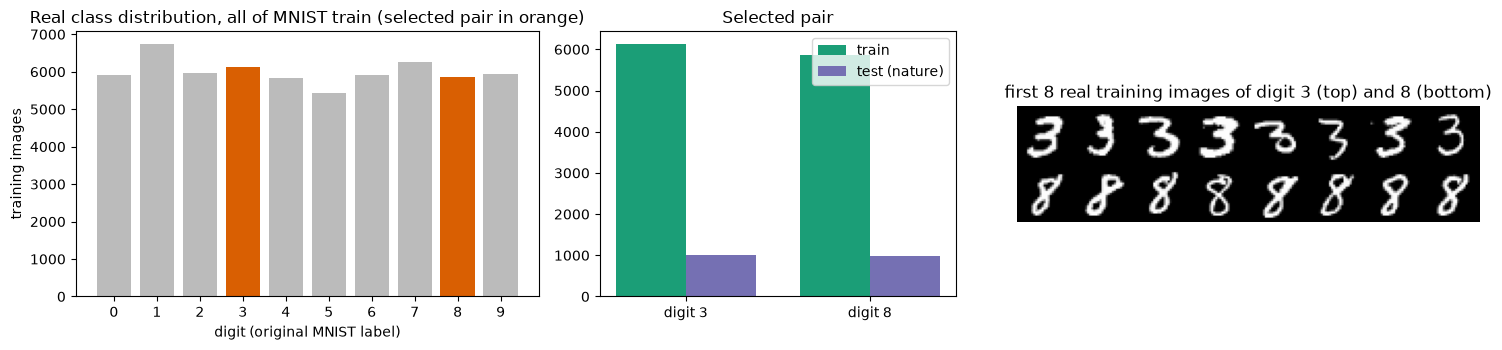

In [7]:
# ---------------- class distribution and example images ----------------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1, 1.3]))
cnt = np.bincount(y_all_tr, minlength=10)
ax[0].bar(range(10), cnt, color=["#d95f02" if d in DIGITS else "#bbbbbb" for d in range(10)])
ax[0].set_xticks(range(10)); ax[0].set_xlabel("digit (original MNIST label)"); ax[0].set_ylabel("training images"); ax[0].set_title("Real class distribution, all of MNIST train (selected pair in orange)")
w = 0.38
ax[1].bar(np.arange(2) - w / 2, [int((ytr_raw == d).sum()) for d in DIGITS], w, label="train", color="#1b9e77")
ax[1].bar(np.arange(2) + w / 2, [int((yte_raw == d).sum()) for d in DIGITS], w, label="test (nature)", color="#7570b3")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels([f"digit {d}" for d in DIGITS]); ax[1].legend(); ax[1].set_title("Selected pair")
ex = np.concatenate([np.concatenate([Xtr[ytr == c][i].reshape(28, 28) for i in range(8)], axis=1) for c in (0, 1)], axis=0)
ax[2].imshow(ex, cmap="gray"); ax[2].axis("off"); ax[2].set_title(f"first 8 real training images of digit {DIGITS[0]} (top) and {DIGITS[1]} (bottom)")
plt.tight_layout(); plt.show()

PCA explained variance ratio: [0.1242 0.078 ]
bit strings of length n = 5 (4 thermometer feature bits + 1 label bit), 32 possible strings, 18 of them occur in the test split;  train 11982 samples, test 1984 samples
d_H(D_train, D_test) = 0.069   <- finite-sample noise floor of any generative model fitted on the training split


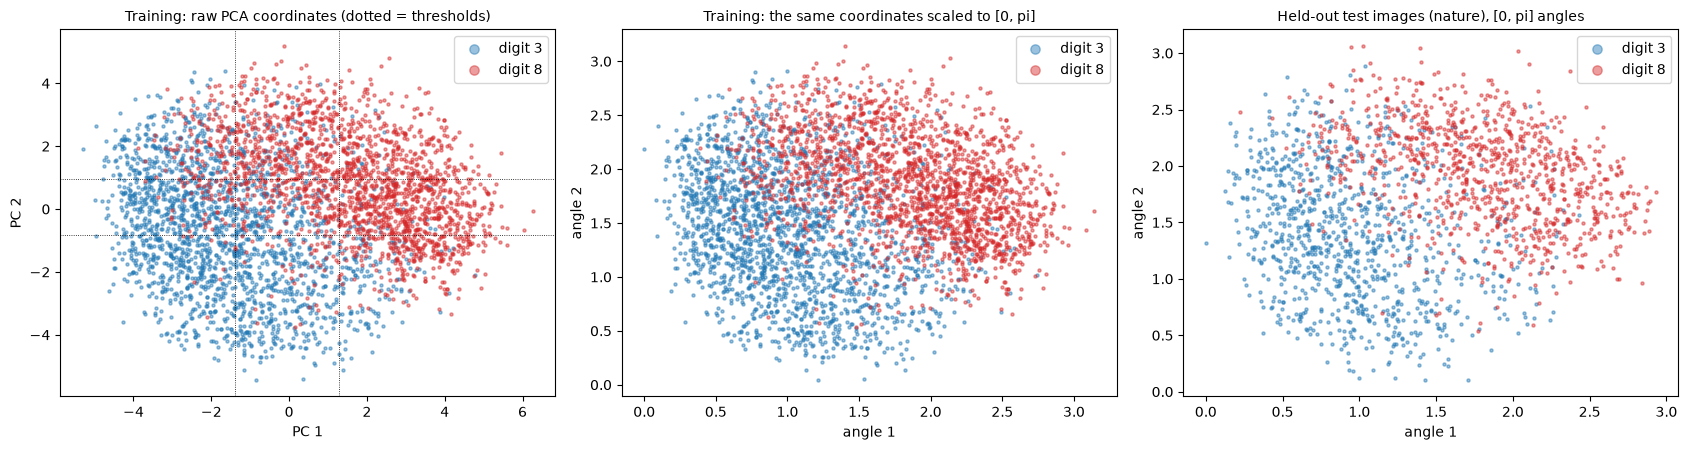

The scatter plots show real MNIST images (one point = one image), coloured by the real digit label.


In [8]:
# ---------------- preprocessing fitted on the training split only: PCA(2) -> quantile thresholds -> thermometer-coded bits ----------------
# CHOICE: every PCA coordinate gets M = THRESH_PER_PC thresholds (quantiles of the TRAINING split) and M bits: bit i = [coordinate > threshold_i].
# A "thermometer" (unary) code makes one flipped bit a one-level move of the input, i.e. a small perturbation, which is the discrete analogue of an l_p ball.
M_T = THRESH_PER_PC; NFEAT = 2 * M_T; NQ = NFEAT + 1; NCELL = 2 ** NFEAT; NSTR = 2 ** NQ
pca = PCA(n_components=2, random_state=SEED).fit(Xtr)                     # fitted on the training split only
Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
print("PCA explained variance ratio:", pca.explained_variance_ratio_.round(4))
qs = np.linspace(0, 1, M_T + 2)[1:-1]
EDGES = [np.quantile(Ptr[:, j], qs) for j in range(2)]                    # thresholds from the training split only
def to_levels(P):
    return np.stack([np.searchsorted(EDGES[j], P[:, j]) for j in range(2)], axis=1)      # level = number of thresholds below the value, 0 .. M
btr, bte = to_levels(Ptr), to_levels(Pte)
# bit string x = therm(level1) + 2^M * therm(level2) + 2^(2M) * label   (qubit j of the circuit = bit j of x; the label is the most significant bit)
def therm(l): l = np.asarray(l); return (1 << l) - 1                     # level l -> l ones in the lowest bits
def encode(bins, y): return therm(bins[:, 0]) + (therm(bins[:, 1]) << M_T) + (y << NFEAT)
def cell_of(x): return x % NCELL                                          # the NFEAT feature bits of a string x
def label_of(x): return x // NCELL
def levels_of_cell(c):
    """(level of PC 1, level of PC 2) read from ANY 2M feature bits as the number of ones in each half: valid thermometer words and
    the invalid words that a bit flip can create are both read this way (this is how the classifier f sees a perturbed input)"""
    c = np.asarray(c); lo = c & (2 ** M_T - 1); hi = c >> M_T
    pop = lambda v: np.array([bin(int(t)).count("1") for t in np.atleast_1d(v)])
    return pop(lo), pop(hi)
def grid_by_bins(v):
    """arrange a vector over the NCELL feature words as a (level of PC 2) x (level of PC 1) array (valid thermometer words), for plotting"""
    return np.array([[v[int(therm(l1)) + (int(therm(l2)) << M_T)] for l1 in range(M_T + 1)] for l2 in range(M_T + 1)])
xtr, xte = encode(btr, ytr), encode(bte, yte)
D_train = np.bincount(xtr, minlength=NSTR) / len(xtr)
D_test = np.bincount(xte, minlength=NSTR) / len(xte)
print(f"bit strings of length n = {NQ} ({NFEAT} thermometer feature bits + 1 label bit), {NSTR} possible strings, {int((D_test > 0).sum())} of them occur in the test split;  train {len(xtr)} samples, test {len(xte)} samples")
print("d_H(D_train, D_test) =", round(hell(D_train, D_test), 4), "  <- finite-sample noise floor of any generative model fitted on the training split")

# raw PCA coordinates, then angles scaled to [0, pi] (fit on train, test clipped), as in the sibling notebooks
sc = MinMaxScaler((0, np.pi)).fit(Ptr)
Atr, Ate = sc.transform(Ptr), np.clip(sc.transform(Pte), 0, np.pi)
sub = np.random.default_rng(SEED).choice(len(Ptr), size=min(4000, len(Ptr)), replace=False)
cols = {0: "#1f77b4", 1: "#d62728"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for c in (0, 1):
    m = ytr[sub] == c
    ax[0].scatter(Ptr[sub][m, 0], Ptr[sub][m, 1], s=5, alpha=.45, c=cols[c], label=f"digit {DIGITS[c]}")
    ax[1].scatter(Atr[sub][m, 0], Atr[sub][m, 1], s=5, alpha=.45, c=cols[c], label=f"digit {DIGITS[c]}")
    m2 = yte == c
    ax[2].scatter(Ate[m2, 0], Ate[m2, 1], s=5, alpha=.45, c=cols[c], label=f"digit {DIGITS[c]}")
for e in EDGES[0]: ax[0].axvline(e, c="k", lw=.6, ls=":")
for e in EDGES[1]: ax[0].axhline(e, c="k", lw=.6, ls=":")
ax[0].set_title("Training: raw PCA coordinates (dotted = thresholds)", fontsize=10); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].set_title("Training: the same coordinates scaled to [0, pi]", fontsize=10); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
ax[2].set_title("Held-out test images (nature), [0, pi] angles", fontsize=10); ax[2].set_xlabel("angle 1"); ax[2].set_ylabel("angle 2")
for a in ax: a.legend(markerscale=3)
plt.tight_layout(); plt.show()
print("The scatter plots show real MNIST images (one point = one image), coloured by the real digit label.")

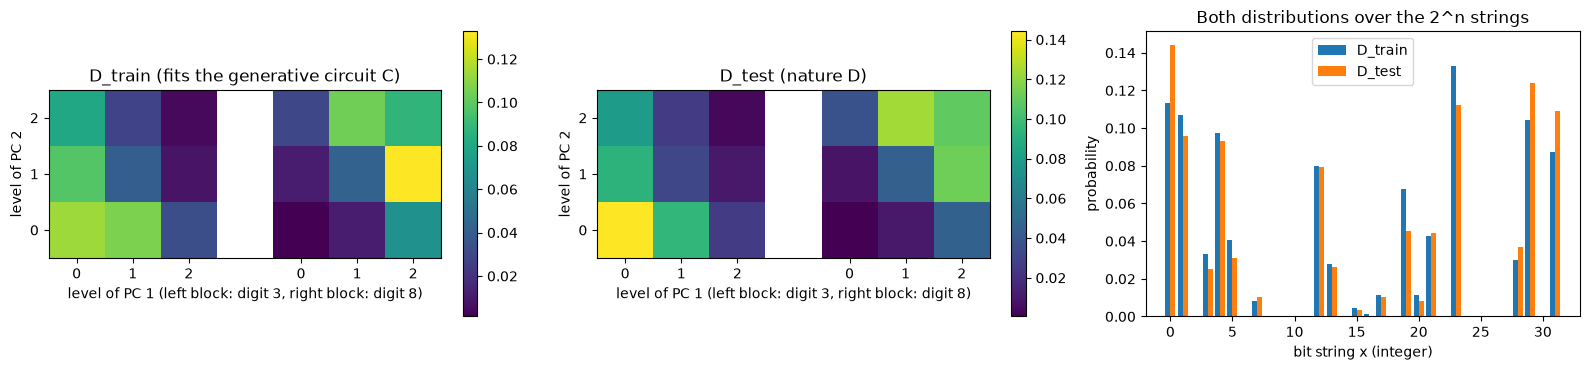

In [9]:
# ---------------- the distributions D_train and D_test over the 2^n bit strings ----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (nm, Dd) in zip(ax[:2], [("D_train (fits the generative circuit C)", D_train), ("D_test (nature D)", D_test)]):
    im = a.imshow(np.concatenate([grid_by_bins(Dd[:NCELL]), np.full((M_T + 1, 1), np.nan), grid_by_bins(Dd[NCELL:])], axis=1), origin="lower", cmap="viridis")
    a.set_title(nm); a.set_xlabel(f"level of PC 1 (left block: digit {DIGITS[0]}, right block: digit {DIGITS[1]})"); a.set_ylabel("level of PC 2"); plt.colorbar(im, ax=a, fraction=.046)
    a.set_xticks(list(range(M_T + 1)) + [M_T + 2 + l for l in range(M_T + 1)]); a.set_xticklabels([str(l) for l in range(M_T + 1)] * 2); a.set_yticks(range(M_T + 1))
ax[2].bar(np.arange(NSTR) - .2, D_train, .4, label="D_train"); ax[2].bar(np.arange(NSTR) + .2, D_test, .4, label="D_test")
ax[2].set_xlabel("bit string x (integer)"); ax[2].set_ylabel("probability"); ax[2].legend(); ax[2].set_title("Both distributions over the 2^n strings")
plt.tight_layout(); plt.show()

## 2. The classifier `f`, the error set `E`, and the classical baselines on identical inputs

The classifier whose robustness we study sees the **4 feature bits** (the two bin indices) and must predict the label bit. We train it on the training split; the error set
`E = {x in {0,1}^5 : f(feature bits of x) != label bit of x}` is a subset of the strings and the standard risk is exactly `R_D(f) = D(E)`.
As the paper's input is not specified we also report baselines on the *same* 4 feature bits and, for reference, on all 784 pixels.

error set E: 16 of 32 strings;  standard risk R_D(f) = D_test(E) = 0.1527  (train 0.1675)


         classifier                           input  test accuracy
SVC rbf (this is f) 4 feature bits (identical to f)         0.8473
       RandomForest 4 feature bits (identical to f)         0.8473
 LogisticRegression 4 feature bits (identical to f)         0.8342
       RandomForest all 784 pixels (reference only)         0.9894
 LogisticRegression all 784 pixels (reference only)         0.9667
(74.9s)


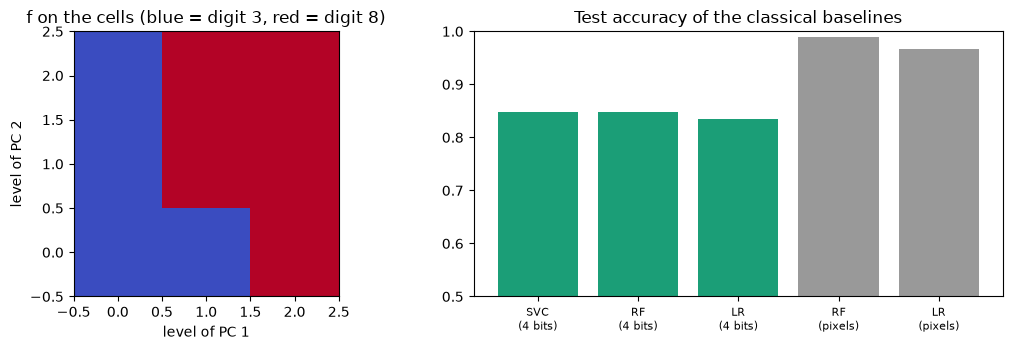

In [10]:
cells = np.arange(NCELL)
def cell_coords(c):                                   # what f sees: (level of PC 1, level of PC 2) = number of ones in each half of the feature word
    l1, l2 = levels_of_cell(c); return np.stack([l1, l2], axis=1).astype(float)
ftr = cell_of(xtr); fte = cell_of(xte)

f_svc = SVC(kernel="rbf", C=10, gamma="scale").fit(cell_coords(ftr), ytr)       # CHOICE: C = 10 (the cell-majority rule is what any of these models learns here)
pred_cell = f_svc.predict(cell_coords(cells)).astype(int)                        # f as a lookup table over the 2^(2B) feature cells
err = np.array([pred_cell[cell_of(x)] != label_of(x) for x in range(NSTR)])    # error set E over all 2^n strings
R_D = float(D_test[err].sum()); R_Dtr = float(D_train[err].sum())
print(f"error set E: {int(err.sum())} of {NSTR} strings;  standard risk R_D(f) = D_test(E) = {R_D:.4f}  (train {R_Dtr:.4f})")

t = time.time()
rows = []
for name, mk in [("SVC rbf (this is f)", lambda: SVC(kernel="rbf", C=10)), ("RandomForest", lambda: RandomForestClassifier(n_estimators=100, random_state=SEED)),
                 ("LogisticRegression", lambda: LogisticRegression(max_iter=500))]:
    m = mk().fit(cell_coords(ftr), ytr)
    rows.append([name, "4 feature bits (identical to f)", float(m.score(cell_coords(fte), yte))])
sub_px = np.random.default_rng(SEED).choice(len(Xtr), size=len(Xtr) if not FAST_MODE else 4000, replace=False)       # FAST: 4000 training images for the pixel baselines
for name, mk in [("RandomForest", lambda: RandomForestClassifier(n_estimators=30 if FAST_MODE else 100, random_state=SEED, n_jobs=1)),
                 ("LogisticRegression", lambda: LogisticRegression(max_iter=300))]:
    m = mk().fit(Xtr[sub_px], ytr[sub_px])
    rows.append([name, "all 784 pixels (reference only)", float(m.score(Xte, yte))])
base = pd.DataFrame(rows, columns=["classifier", "input", "test accuracy"])
print(base.round(4).to_string(index=False)); print(f"({time.time()-t:.1f}s)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].imshow(grid_by_bins(pred_cell), origin="lower", cmap="coolwarm", vmin=0, vmax=1)
ax[0].set_title(f"f on the cells (blue = digit {DIGITS[0]}, red = digit {DIGITS[1]})"); ax[0].set_xlabel("level of PC 1"); ax[0].set_ylabel("level of PC 2")
ax[1].bar(range(len(base)), base["test accuracy"], color=["#1b9e77"] * 3 + ["#999999"] * 2); ax[1].set_xticks(range(len(base)))
ax[1].set_xticklabels(["SVC\n(4 bits)", "RF\n(4 bits)", "LR\n(4 bits)", "RF\n(pixels)", "LR\n(pixels)"], fontsize=8); ax[1].set_ylim(.5, 1); ax[1].set_title("Test accuracy of the classical baselines")
plt.tight_layout(); plt.show()

## 3. Classical threat models on the same data: exact Hamming-ball adversaries and bit-flip randomised smoothing

*Adversary.* The discrete analogue of an `l_p` ball for bit strings is the **Hamming ball**: the adversary may flip up to `k` of the 4 feature bits of an input (the label bit is the truth and is not touched).
Because `n = 5` we can enumerate the ball exactly, so this is the **worst-case** adversary, not a heuristic attack: `R_k = D(E_k)` with `E_k` the strings from which an error string is within `k` flips.
The paper's motivation is that `R_k` can be far larger than `R_0 = R_D(f)`.

*Classical certificate.* **Randomised smoothing** replaces `f` by the majority vote of `f` over noisy copies of the input; for Gaussian noise it certifies an `l_2` radius, for random bit flips it certifies a Hamming radius
(Lee et al. 2019). With flip probability `rho` and `p_A` the probability of the winning class under the noise, the exact certified radius follows from the Neyman-Pearson lemma: the likelihood ratio between the noise laws centred at two inputs `r` bits apart depends only on how many of the `r` differing
bits flipped, so the worst set can be filled in that order. We compute it **exactly** (no sampling) and verify it by brute force over every Hamming ball.

In [11]:
FB = NFEAT                                              # number of feature bits
xs = np.arange(NSTR)
def hamming_reach(err_mask, kmax):
    """dist[x] = fewest feature-bit flips (label bit fixed) that turn x into an error string (0 if x is one, inf if none within kmax);
    target[x] = that error string.  Synchronous BFS over the 2^n strings: exact."""
    dist = np.where(err_mask, 0.0, np.inf); target = np.where(err_mask, xs, -1)
    for _ in range(kmax):
        nd, nt = dist.copy(), target.copy()
        for j in range(FB):
            nb = xs ^ (1 << j)
            better = dist[nb] + 1 < nd
            nd = np.where(better, dist[nb] + 1, nd); nt = np.where(better, target[nb], nt)
        dist, target = nd, nt
    return dist, target
dist_err, tgt_err = hamming_reach(err, FB)
adv_rows = []
for k in range(FB + 1):
    Rk = float(D_test[dist_err <= k].sum())
    adv_rows.append([k, Rk, Rk / max(R_D, 1e-12)])
adv = pd.DataFrame(adv_rows, columns=["Hamming radius k", "adversarial risk R_k = D(E_k)", "ratio R_k / R_0"])
print(adv.round(4).to_string(index=False))

def pushforward(D, k, q=1.0):
    """Distribution after an adversary that moves a fraction q of the mass of every non-error string x with dist<=k to its nearest error string."""
    Dp = np.array(D, dtype=float)
    for x in range(NSTR):
        if 0 < dist_err[x] <= k:
            Dp[x] -= q * D[x]; Dp[int(tgt_err[x])] += q * D[x]
    return Dp
for k in (1, 2):
    Dk = pushforward(D_test, k)
    print(f"adversary k={k} applied to every input: risk {Dk[err].sum():.4f}, d_H(D, D') = {hell(D_test, Dk):.4f}, TV = {tvd(D_test, Dk):.4f}")

 Hamming radius k  adversarial risk R_k = D(E_k)  ratio R_k / R_0
                0                         0.1527           1.0000
                1                         0.6346           4.1551
                2                         1.0000           6.5479
                3                         1.0000           6.5479
                4                         1.0000           6.5479
adversary k=1 applied to every input: risk 0.6346, d_H(D, D') = 0.5846, TV = 0.4819
adversary k=2 applied to every input: risk 1.0000, d_H(D, D') = 0.8013, TV = 0.8473


 flip prob rho  smoothed clean acc  certified acc r=1  certified acc r=2  certified acc r=3  exact adv. acc r=1  exact adv. acc r=2  exact adv. acc r=3  soundness violations
          0.05              0.8473             0.3654                0.0                0.0              0.3654                 0.0                 0.0                     0
          0.10              0.8473             0.3654                0.0                0.0              0.3654                 0.0                 0.0                     0
          0.20              0.8473             0.2213                0.0                0.0              0.3654                 0.0                 0.0                     0


base classifier f, exact Hamming-ball accuracy: {0: 0.8473, 1: 0.3654, 2: 0.0, 3: 0.0, 4: 0.0}


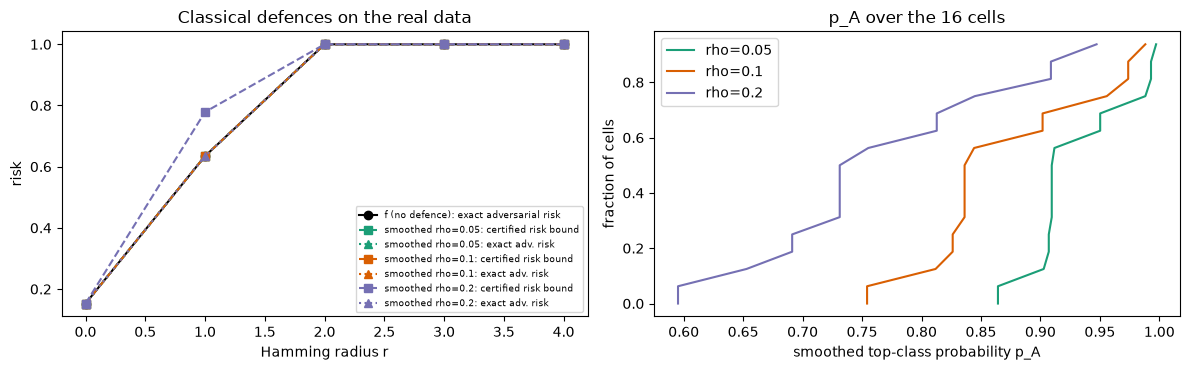

In [12]:
from math import comb
def rs_lower(r, pA, rho):
    """Exact lower bound of P_{x'}(A) over all sets A with P_x(A) >= pA when x and x' differ in r bits and each bit flips with prob rho<1/2 (Neyman-Pearson)."""
    if r == 0: return pA
    ks = np.arange(0, r + 1)
    mx = np.array([comb(r, k) * rho ** k * (1 - rho) ** (r - k) for k in ks])          # mass under x of 'k of the r bits flipped'
    mxp = np.array([comb(r, k) * rho ** (r - k) * (1 - rho) ** k for k in ks])          # the same event under x'
    acc = out = 0.0
    for k in ks:                                                                       # smallest likelihood ratio P_x'/P_x first (k = 0, 1, ...)
        take = min(mx[k], pA - acc)
        if take <= 1e-15: break
        out += mxp[k] * take / mx[k]; acc += take
    return out
def rs_radius(pA, rho):
    R = -1
    for r in range(0, FB + 1):
        if rs_lower(r, pA, rho) > 0.5 + 1e-12: R = r
        else: break
    return R                                                                           # -1: no certificate (pA <= 1/2)

zs = np.arange(NCELL)
def smoothed_p1(rho):
    """P(f(u xor z) = 1) for every feature cell u, z ~ iid Bernoulli(rho) on the feature bits (exact, 2^(2B) x 2^(2B))."""
    P = np.zeros(NCELL)
    for u in range(NCELL):
        w = np.array([rho ** bin(u ^ v).count("1") * (1 - rho) ** (FB - bin(u ^ v).count("1")) for v in range(NCELL)])
        P[u] = (w * pred_cell).sum()
    return P
RS = {}
rs_tab = []
for rho in SMOOTH_RHOS:
    p1 = smoothed_p1(rho); chat = (p1 > 0.5).astype(int); pA = np.maximum(p1, 1 - p1)
    Rad = np.array([rs_radius(pA[u], rho) for u in range(NCELL)])
    # brute-force soundness: no input inside the certified Hamming ball changes the smoothed prediction
    viol = 0; flipdist = np.full(NCELL, 99)
    for u in range(NCELL):
        for v in range(NCELL):
            dd = bin(u ^ v).count("1")
            if chat[v] != chat[u]: flipdist[u] = min(flipdist[u], dd)
            if Rad[u] >= 0 and dd <= Rad[u] and chat[v] != chat[u]: viol += 1
    RS[rho] = dict(p1=p1, chat=chat, pA=pA, Rad=Rad, viol=viol, flipdist=flipdist)
    clean_acc = float(sum(D_test[x] for x in range(NSTR) if chat[cell_of(x)] == label_of(x)))
    cert = {r: float(sum(D_test[x] for x in range(NSTR) if chat[cell_of(x)] == label_of(x) and Rad[cell_of(x)] >= r)) for r in range(0, FB + 1)}
    # exact worst-case accuracy of the SMOOTHED classifier under the Hamming-r adversary (brute force)
    adv_acc = {r: float(sum(D_test[x] for x in range(NSTR) if all(chat[v] == label_of(x) for v in range(NCELL) if bin(cell_of(x) ^ v).count("1") <= r))) for r in range(0, FB + 1)}
    RS[rho].update(clean_acc=clean_acc, cert=cert, adv_acc=adv_acc)
    rs_tab.append([rho, clean_acc, *[cert[r] for r in range(1, 4)], *[adv_acc[r] for r in range(1, 4)], viol])
rs_df = pd.DataFrame(rs_tab, columns=["flip prob rho", "smoothed clean acc", "certified acc r=1", "certified acc r=2", "certified acc r=3",
                                      "exact adv. acc r=1", "exact adv. acc r=2", "exact adv. acc r=3", "soundness violations"])
print(rs_df.round(4).to_string(index=False))
base_adv_acc = {r: 1 - float(D_test[dist_err <= r].sum()) for r in range(FB + 1)}
print("base classifier f, exact Hamming-ball accuracy:", {r: round(v, 4) for r, v in base_adv_acc.items()})
assert all(RS[r]["viol"] == 0 for r in SMOOTH_RHOS), "randomised-smoothing certificate violated"
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(range(FB + 1), [1 - base_adv_acc[r] for r in range(FB + 1)], "ko-", label="f (no defence): exact adversarial risk")
for rho, c in zip(SMOOTH_RHOS, ["#1b9e77", "#d95f02", "#7570b3"]):
    ax[0].plot(range(FB + 1), [1 - RS[rho]["cert"][r] for r in range(FB + 1)], "s--", c=c, label=f"smoothed rho={rho}: certified risk bound")
    ax[0].plot(range(FB + 1), [1 - RS[rho]["adv_acc"][r] for r in range(FB + 1)], "^:", c=c, label=f"smoothed rho={rho}: exact adv. risk")
ax[0].set_xlabel("Hamming radius r"); ax[0].set_ylabel("risk"); ax[0].set_title("Classical defences on the real data"); ax[0].legend(fontsize=6.5)
for rho, c in zip(SMOOTH_RHOS, ["#1b9e77", "#d95f02", "#7570b3"]):
    ax[1].plot(np.sort(RS[rho]["pA"]), np.arange(NCELL) / NCELL, c=c, label=f"rho={rho}")
ax[1].set_xlabel("smoothed top-class probability p_A"); ax[1].set_ylabel("fraction of cells"); ax[1].set_title("p_A over the 16 cells"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. The generative circuit `C` (a quantum circuit Born machine) and the distance `eta`

The protocol needs a circuit `C` with `D_C = |<x|U_C|0^n>|^2` close to nature's distribution. We train `real_amplitudes(n, reps)` on the **training** split to maximise `sum_x sqrt(D_train(x) D_C(x)) = 1 - d_H^2` and then measure
`eta = d_H(D_test, D_C)` on the held-out split. For speed the training loop uses a small NumPy simulator of this ansatz; it is **asserted equal to the Qiskit statevector** of the very same parameters
(next cell), and everything that follows uses the Qiskit circuit.

NumPy QCBM simulator == Qiskit statevector (5 random parameter vectors, max |difference| < 1e-12);  25 trainable parameters


adjoint gradient of the overlap == finite differences (max error < 1e-7)


restarts (overlap sum sqrt(D_train D_C)): [0.99955 0.99903 0.99961 0.99974 0.99486 0.99894]  (57.3s)
d_H(D_train, D_C) = 0.0161   eta = d_H(D_test, D_C) = 0.0708   (noise floor d_H(D_train, D_test) = 0.0690)
protocol parameter eta = 0.08   threshold on the average out bit: 1 - 2 eta^2 = 0.9872
risk of f under the model D_C: R_C = 0.1688;   risk under nature: R_D = 0.1527


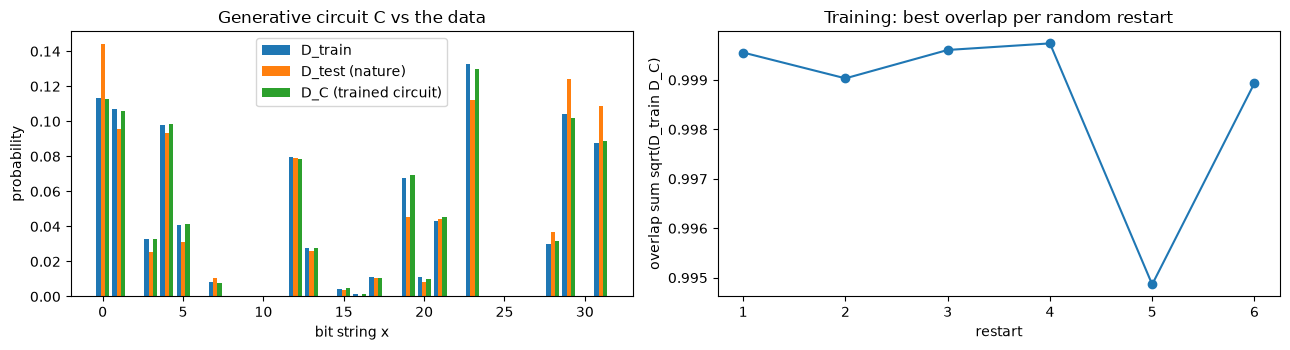

In [13]:
def make_qcbm_sim(n, reps):
    """NumPy simulator of real_amplitudes(n, reps, entanglement='linear') (Ry layers, CX(q,q+1) chains), little endian."""
    ry = lambda t: np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.sin(t / 2), np.cos(t / 2)]])
    idx = np.arange(2 ** n); cur = idx.copy()
    for q in range(n - 1):                                    # push every basis index through CX(q, q+1) in circuit order
        cur = np.where(((cur >> q) & 1) == 1, cur ^ (1 << (q + 1)), cur)
    inv = np.empty_like(cur); inv[cur] = idx
    def layer(thl):
        M_ = np.array([[1.0]])
        for q in range(len(thl)): M_ = np.kron(ry(thl[q]), M_)       # qubit 0 is the least significant tensor factor
        return M_
    def sim(th):
        st = np.zeros(2 ** n); st[0] = 1.0
        for r in range(reps + 1):
            st = layer(th[r * n:(r + 1) * n]) @ st
            if r < reps: st = st[inv]
        return st
    def overlap_and_grad(th, tgt):
        """F = <tgt|psi(theta)> and dF/dtheta by reverse-mode (adjoint) differentiation; d/dtheta Ry(theta) = Ry(theta + pi)/2."""
        mats = [layer(th[r * n:(r + 1) * n]) for r in range(reps + 1)]; pres = []; st = np.zeros(2 ** n); st[0] = 1.0
        for r in range(reps + 1):
            pres.append(st); mid = mats[r] @ st
            st = mid[inv] if r < reps else mid
        F = float(tgt @ mid); b = tgt.copy(); grad = np.zeros_like(th)
        for r in range(reps, -1, -1):
            for q in range(n):
                thl = th[r * n:(r + 1) * n].copy(); thl[q] += np.pi
                grad[r * n + q] = 0.5 * float(b @ (layer(thl) @ pres[r]))
            if r > 0: b = (mats[r].T @ b)[cur]
        return F, grad
    sim.overlap_and_grad = overlap_and_grad
    return sim

sim_C = make_qcbm_sim(NQ, QCBM_REPS)
ansatz = real_amplitudes(NQ, reps=QCBM_REPS, entanglement="linear")
NPAR = ansatz.num_parameters
for _ in range(5):
    th = np.random.default_rng(SEED + _).uniform(-3, 3, NPAR)
    sv = Statevector(ansatz.assign_parameters(th)).data
    assert np.abs(sv - sim_C(th)).max() < 1e-12, "NumPy simulator differs from the Qiskit statevector"
print(f"NumPy QCBM simulator == Qiskit statevector (5 random parameter vectors, max |difference| < 1e-12);  {NPAR} trainable parameters")

target_amp = np.sqrt(D_train)
th_t = np.random.default_rng(SEED + 99).uniform(-3, 3, NPAR)                      # the analytic gradient is checked against central finite differences
g_fd = np.array([(sim_C(th_t + 1e-6 * e) @ target_amp - sim_C(th_t - 1e-6 * e) @ target_amp) / 2e-6 for e in np.eye(NPAR)])
assert np.abs(sim_C.overlap_and_grad(th_t, target_amp)[1] - g_fd).max() < 1e-7 and abs(sim_C.overlap_and_grad(th_t, target_amp)[0] - sim_C(th_t) @ target_amp) < 1e-12
print("adjoint gradient of the overlap == finite differences (max error < 1e-7)")
def neg_abs_overlap(th):
    F, g = sim_C.overlap_and_grad(th, target_amp); s = 1.0 if F >= 0 else -1.0
    return -s * F, -s * g
t = time.time(); best = None; hist = []
rs_ = np.random.default_rng(SEED)
for r_ in range(QCBM_RESTARTS):
    res = minimize(neg_abs_overlap, rs_.uniform(-np.pi, np.pi, NPAR), jac=True, method="L-BFGS-B", options=dict(maxiter=QCBM_MAXITER))
    hist.append(-res.fun)
    if best is None or res.fun < best.fun: best = res
theta_star = best.x
raw_amp = sim_C(theta_star)                              # amplitudes of U|0^n> before the sign gate (some may be negative)
sgn0 = 1.0 if raw_amp[np.argmax(np.abs(raw_amp))] >= 0 else -1.0       # a global sign is a global phase and irrelevant
signs = np.where(raw_amp * sgn0 >= 0, 1.0, -1.0)         # CHOICE: a final diagonal +-1 gate makes all amplitudes >= 0 (up to a global sign), as the paper's |psi_DC> = sum sqrt(D_C(x))|x> requires
D_C = raw_amp ** 2; D_C = D_C / D_C.sum()
eta_train, eta_test = hell(D_train, D_C), hell(D_test, D_C)
print(f"restarts (overlap sum sqrt(D_train D_C)): {np.round(hist, 5)}  ({time.time()-t:.1f}s)")
print(f"d_H(D_train, D_C) = {eta_train:.4f}   eta = d_H(D_test, D_C) = {eta_test:.4f}   (noise floor d_H(D_train, D_test) = {hell(D_train, D_test):.4f})")
ETA = float(np.ceil(eta_test * 100) / 100)          # CHOICE: the protocol parameter eta is eta_test rounded UP to 0.01 so that the completeness assumption d_H(D, D_C) <= eta holds
print("protocol parameter eta =", ETA, "  threshold on the average out bit: 1 - 2 eta^2 =", round(1 - 2 * ETA ** 2, 5))
R_C = float(D_C[err].sum())
print(f"risk of f under the model D_C: R_C = {R_C:.4f};   risk under nature: R_D = {R_D:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(np.arange(NSTR) - .27, D_train, .27, label="D_train"); ax[0].bar(np.arange(NSTR), D_test, .27, label="D_test (nature)"); ax[0].bar(np.arange(NSTR) + .27, D_C, .27, label="D_C (trained circuit)")
ax[0].set_xlabel("bit string x"); ax[0].set_ylabel("probability"); ax[0].legend(); ax[0].set_title("Generative circuit C vs the data")
ax[1].plot(range(1, len(hist) + 1), hist, "o-"); ax[1].set_xlabel("restart"); ax[1].set_ylabel("overlap sum sqrt(D_train D_C)"); ax[1].set_title("Training: best overlap per random restart")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every gate-based circuit that the notebook executes is drawn here from the objects that are actually simulated:

1. the **generative circuit `C`** with the trained parameters (`real_amplitudes`, linear entanglement);
2. the **comparison circuit `G`** of Figure 2 around that `C`, with the prover's state `|psi_DA>` prepared on the `adv` register, exactly as it is evolved in the checks (the data states are loaded as the initial statevector of the same circuit without the preparation box; the next cells assert that both give the same output probability);
3. the **toy comparison circuit** (`n = 2`, a 5-gate `C`) used for the circuit-to-Hamiltonian check of Section 8, fully decomposed into the gates `u, cx, h, cswap, x`.

Encoding: the data enter as the *amplitudes* `sqrt(D(x))` of `|psi_D>` (quantum sample), the generative circuit is `Ry` rotations and a CX ladder, the entanglement between `adv` and `aux` is the controlled-SWAP, and the only measurement is the `out` qubit in the Z basis. The paper does not fix `C` or the gate set of `G` beyond Figure 2; the choices (linear `real_amplitudes`, `H` on `out`, one `cswap` per qubit pair, `H`, `X`) follow Figure 2 and Section 4.2 (`T' = n + T + 3` gates).

sign gate: 5 of 32 amplitudes of U_C|0^n> had the minority sign; after the gate all amplitudes have the same sign and D_C is unchanged


C : 5 qubits, depth 68 (native u/cx), 25 trainable parameters (frozen after training), 102 native gates {'u': 56, 'cx': 46}
G : 11 qubits (1 out + 5 adv + 5 aux), depth 96 in the native gates u/cx, 0 trainable parameters (C's 25 are frozen), 190 native gates {'u': 104, 'cx': 86}
In the sense of Section 4.2: T = 102 gates in C, T' = n + T + 3 = 110 gates in G


P(out=1) for |psi_D_test>:  drawn circuit (with StatePreparation) 0.995003630071   evolved circuit (initial statevector) 0.995003630071
1) the generative circuit C (frozen real_amplitudes + diagonal sign gate):


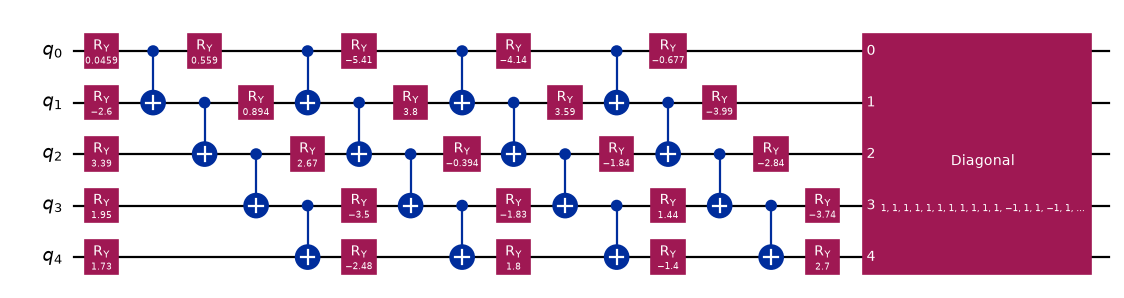

   the same ansatz one level decomposed (Ry layers and the CX ladder):


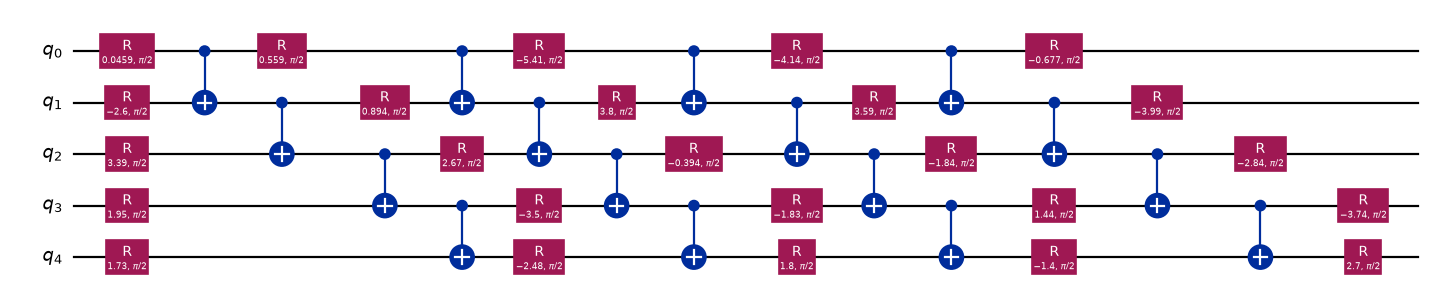

2) the comparison circuit G of Figure 2 with the prover's state |psi_D> on adv (this is what is evolved):


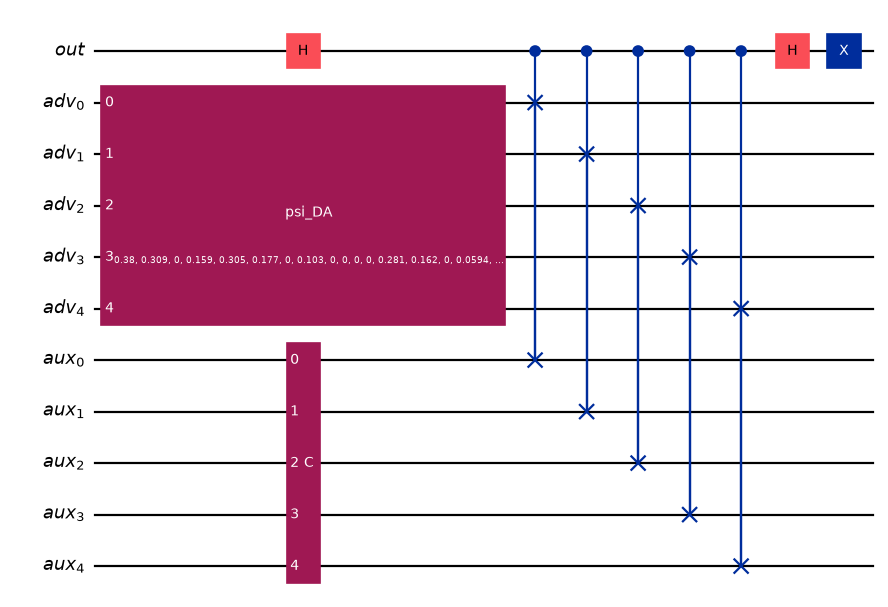

In [14]:
from qiskit import transpile
from qiskit.circuit.library import DiagonalGate
C_circ = QuantumCircuit(NQ)                                      # the trained generative circuit U_C: real_amplitudes with frozen angles + the +-1 sign gate
C_circ.compose(ansatz.assign_parameters(theta_star), inplace=True); C_circ.append(DiagonalGate(list(signs)), range(NQ))
psiC_final = Statevector(C_circ).data
assert np.abs(psiC_final.imag).max() < 1e-12 and (sgn0 * psiC_final.real).min() > -1e-12 and np.allclose(sgn0 * psiC_final.real, np.abs(raw_amp), atol=1e-12)
print(f"sign gate: {int((signs < 0).sum())} of {NSTR} amplitudes of U_C|0^n> had the minority sign; after the gate all amplitudes have the same sign and D_C is unchanged")
G = comparison_circuit(C_circ, NQ)                              # Figure 2 (prover state enters as the initial statevector)
G_draw = comparison_circuit(C_circ, NQ, adv_amplitudes=np.sqrt(D_test))   # same circuit with the state-preparation box for |psi_D>
C_nat = transpile(C_circ, basis_gates=["u", "cx"], optimization_level=0); G_native = transpile(G, basis_gates=["u", "cx"], optimization_level=0)
print(f"C : {C_circ.num_qubits} qubits, depth {C_nat.depth()} (native u/cx), {NPAR} trainable parameters (frozen after training), {C_nat.size()} native gates {dict(C_nat.count_ops())}")
print(f"G : {G.num_qubits} qubits (1 out + {NQ} adv + {NQ} aux), depth {G_native.depth()} in the native gates u/cx, 0 trainable parameters (C's {NPAR} are frozen), {G_native.size()} native gates {dict(G_native.count_ops())}")
print(f"In the sense of Section 4.2: T = {C_nat.size()} gates in C, T' = n + T + 3 = {NQ + C_nat.size() + 3} gates in G")
# circuit equivalence: state-preparation version == initial-statevector version
pp_prep = float(Statevector.from_instruction(G_draw).probabilities([0])[1]); pp_init = p_out1(D_test, G, NQ)
print(f"P(out=1) for |psi_D_test>:  drawn circuit (with StatePreparation) {pp_prep:.12f}   evolved circuit (initial statevector) {pp_init:.12f}")
assert abs(pp_prep - pp_init) < 1e-9
print("1) the generative circuit C (frozen real_amplitudes + diagonal sign gate):"); display(C_circ.draw("mpl", fold=40, scale=.8))
print("   the same ansatz one level decomposed (Ry layers and the CX ladder):"); display(ansatz.assign_parameters(theta_star).decompose().draw("mpl", fold=40, scale=.8))
print("2) the comparison circuit G of Figure 2 with the prover's state |psi_D> on adv (this is what is evolved):"); display(G_draw.draw("mpl", fold=40, scale=.8))

toy G: 5 qubits, 10 gates (= n + T + 3 = 2 + 5 + 3), depth 7, 4 angles inside C (fixed), gates {'u': 4, 'h': 2, 'cswap': 2, 'cx': 1, 'x': 1}
3) the toy comparison circuit used in Section 8:


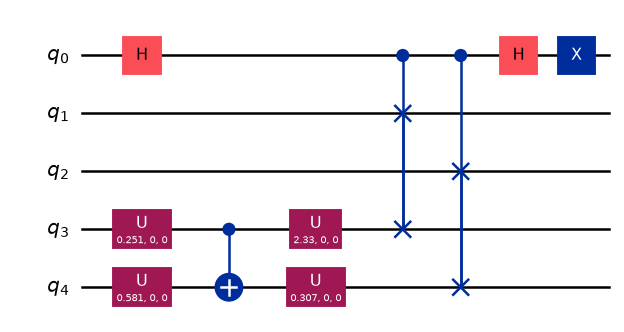

In [15]:
# toy comparison circuit for the circuit-to-Hamiltonian check (Section 8): n = 2, C = real_amplitudes(2, reps=1) with fixed random angles
rt = np.random.default_rng(SEED + 7)
C_toy_param = real_amplitudes(HIST_N, reps=HIST_REPS, entanglement="linear")
while True:                                                             # CHOICE: draw angles until U_C|0^n> has non-negative amplitudes (the paper's |psi_DC>)
    C_toy = transpile(C_toy_param.assign_parameters(rt.uniform(0.2, 2.9, C_toy_param.num_parameters)), basis_gates=["u", "cx"], optimization_level=0)
    if Statevector(C_toy).data.real.min() > -1e-12: break
G_toy = QuantumCircuit(2 * HIST_N + 1)                                  # qubit 0 = out, 1..n = adv, n+1..2n = aux
G_toy.compose(C_toy, qubits=list(range(HIST_N + 1, 2 * HIST_N + 1)), inplace=True)
G_toy.h(0)
for j in range(HIST_N): G_toy.cswap(0, 1 + j, HIST_N + 1 + j)
G_toy.h(0); G_toy.x(0)
T_toy = C_toy.size(); TP_toy = G_toy.size()
print(f"toy G: {G_toy.num_qubits} qubits, {TP_toy} gates (= n + T + 3 = {HIST_N} + {T_toy} + 3), depth {G_toy.depth()}, {C_toy_param.num_parameters} angles inside C (fixed), gates {dict(G_toy.count_ops())}")
assert TP_toy == HIST_N + T_toy + 3
print("3) the toy comparison circuit used in Section 8:"); display(G_toy.draw("mpl", fold=40, scale=.9))

## 5. Section 2 inequalities, Lemma 1 and Corollary 1 on the real circuit (claims V1, V2)

**V1.** The paper states `d_H^2 <= TV <= sqrt(2) d_H` and the identity `1 - d_H^2 = sum sqrt(P Q)`. **V2.** Lemma 1 says that the `out` qubit of `G` is 1 with probability `(1 + |<psi_DA|psi_DC>|^2)/2`; Corollary 1 turns this into `f(d_H) = (1 + (1 - d_H^2)^2)/2`.
Corollary 1 needs `|psi_DC> = sum sqrt(D_C(x)) |x>` to have **non-negative amplitudes** (the paper defines the quantum sample that way). A generic circuit produces signed amplitudes; then only the Lemma 1 form (with the actual overlap) holds and
Corollary 1 over-estimates the acceptance probability. We test both the signed and the non-negative case, and fix the trained `C` by a final diagonal sign gate (a unitary, so `C` is still a circuit).

In [16]:
# ---------------- V1: elementary inequalities ----------------
rs1 = np.random.default_rng(SEED + 1)
va = vb = vc = 0; max_id = 0.0; max_ratio = 0.0; max_hr = 0.0
for _ in range(N_PREL):
    K_ = int(rs1.choice([4, 8, 32])); al = rs1.choice([0.05, 0.3, 1.0, 5.0], 2)
    P_ = rs1.dirichlet(np.ones(K_) * al[0]); Q_ = rs1.dirichlet(np.ones(K_) * al[1])
    h_ = hell(P_, Q_); tv_ = tvd(P_, Q_); bc_ = np.sum(np.sqrt(P_ * Q_))
    va += h_ * h_ > tv_ + 1e-12; vb += tv_ > np.sqrt(2) * h_ + 1e-12; vc += tv_ > h_ * np.sqrt(2 - h_ * h_) + 1e-12
    max_id = max(max_id, abs((1 - h_ * h_) - bc_)); max_ratio = max(max_ratio, tv_ / (np.sqrt(2) * h_ + 1e-300)); max_hr = max(max_hr, h_ * h_ / (tv_ + 1e-300))
e1 = np.array([1.0, 0, 0, 0]); e2 = np.array([0, 1.0, 0, 0])
assert hell(e1, e1) == 0 and abs(hell(e1, e2) - 1) < 1e-12 and tvd(e1, e2) == 1
print(f"{N_PREL} random pairs: violations of d_H^2<=TV: {va}, of TV<=sqrt(2) d_H: {vb}, of the sharper TV<=d_H sqrt(2-d_H^2): {vc};  max |(1-d_H^2)-sum sqrt(PQ)| = {max_id:.1e}")
print(f"largest observed TV/(sqrt(2) d_H) = {max_ratio:.4f}  (1 would be tight),  largest d_H^2/TV = {max_hr:.4f}")
verdict("V1", "Section 2: d_H^2 <= TV <= sqrt(2) d_H and 1-d_H^2 = sum sqrt(PQ)", "stated (standard)", f"{N_PREL} random pairs, 0 violations, identity error {max_id:.1e}",
        "reproduced" if (va + vb + vc == 0 and max_id < 1e-12) else "not reached")

20000 random pairs: violations of d_H^2<=TV: 0, of TV<=sqrt(2) d_H: 0, of the sharper TV<=d_H sqrt(2-d_H^2): 0;  max |(1-d_H^2)-sum sqrt(PQ)| = 1.7e-16
largest observed TV/(sqrt(2) d_H) = 0.9923  (1 would be tight),  largest d_H^2/TV = 1.0000
[V1] REPRODUCED: 20000 random pairs, 0 violations, identity error 1.7e-16


In [17]:
# ---------------- V2: Lemma 1 / Corollary 1 on the Qiskit circuit ----------------
def p_out1_state(psi, G_, n):
    """Same as p_out1 but for an arbitrary complex amplitude vector psi of the prover's n-qubit state."""
    psi = np.asarray(psi, dtype=complex); psi = psi / np.linalg.norm(psi)
    init = np.kron(np.eye(2 ** n)[0], np.kron(psi, np.array([1.0, 0.0])))
    return float(Statevector(init).evolve(G_).probabilities([0])[1])

def random_prover_dist(K_, rg):
    kind = rg.integers(0, 4); a = rg.choice([0.05, 0.3, 1.0, 5.0])
    if kind == 0: return rg.dirichlet(np.ones(K_) * a)
    if kind == 1: v = np.zeros(K_); v[rg.integers(K_)] = 1.0; return v                  # a single basis string (a "nice-looking" cheat)
    if kind == 2: return 0.5 * rg.dirichlet(np.ones(K_) * a) + 0.5 * rg.dirichlet(np.ones(K_))
    return rg.dirichlet(np.ones(K_) * a)

rs2 = np.random.default_rng(SEED + 2); n3 = 3
res = dict(l1_nonneg=0.0, c1_nonneg=0.0, l1_signed=0.0, c1_signed=0.0, bound_phase=0.0)
signed_gap = []
for t_ in range(N_PAIRS_RANDOM):
    # (i) C prepares a non-negative amplitude vector sqrt(D_C) exactly (generative model with perfect state preparation)
    DCr = rs2.dirichlet(np.ones(2 ** n3) * rs2.choice([0.2, 1.0, 4.0]))
    Cr = QuantumCircuit(n3); Cr.append(StatePreparation(np.sqrt(DCr)), range(n3)); Gr = comparison_circuit(Cr, n3)
    DAr = random_prover_dist(2 ** n3, rs2); pc = p_out1(DAr, Gr, n3)
    psiC_ = Statevector(Cr).data
    res["l1_nonneg"] = max(res["l1_nonneg"], abs(pc - 0.5 * (1 + abs(np.vdot(np.sqrt(DAr), psiC_)) ** 2)))
    res["c1_nonneg"] = max(res["c1_nonneg"], abs(pc - float(f_acc(hell(DAr, DCr)))))
    # (ii) C = random real_amplitudes circuit: signed amplitudes
    th_ = rs2.uniform(-np.pi, np.pi, real_amplitudes(n3, reps=2).num_parameters)
    Cs = real_amplitudes(n3, reps=2, entanglement="linear").assign_parameters(th_); Gs = comparison_circuit(Cs, n3)
    psiCs = Statevector(Cs).data; DCs = np.abs(psiCs) ** 2
    pc2 = p_out1(DAr, Gs, n3)
    res["l1_signed"] = max(res["l1_signed"], abs(pc2 - 0.5 * (1 + abs(np.vdot(np.sqrt(DAr), psiCs)) ** 2)))
    res["c1_signed"] = max(res["c1_signed"], abs(pc2 - float(f_acc(hell(DAr, DCs)))))
    signed_gap.append(float(f_acc(hell(DAr, DCs))) - pc2)
    # (iii) a prover that adds arbitrary phases can only lower the acceptance probability: P <= f(d_H)
    ph = np.exp(1j * rs2.uniform(0, 2 * np.pi, 2 ** n3)) * np.sqrt(DAr)
    res["bound_phase"] = max(res["bound_phase"], p_out1_state(ph, Gr, n3) - float(f_acc(hell(DAr, DCr))))
print(f"n = {n3} (7-qubit circuits), {N_PAIRS_RANDOM} random (C, state) pairs of each kind:")
print(f"  non-negative C : max |P_circuit - Lemma 1| = {res['l1_nonneg']:.2e},  max |P_circuit - Corollary 1| = {res['c1_nonneg']:.2e}")
print(f"  signed C       : max |P_circuit - Lemma 1| = {res['l1_signed']:.2e},  max |P_circuit - Corollary 1| = {res['c1_signed']:.3f}  (mean shortfall of the real circuit vs f(d_H): {np.mean(signed_gap):.3f})")
print(f"  random phases  : max (P_circuit - f(d_H)) = {res['bound_phase']:.2e}  (<= 0 means phases never help the prover)")

# the trained C of this notebook (real_amplitudes + diagonal sign gate, built in the circuit section) has non-negative amplitudes
assert (sgn0 * Statevector(C_circ).data.real).min() > -1e-12

# real data states (n = 5, 11 qubits): D_test, D_train, D_C, classical-attack pushforwards, random mixtures
rs3 = np.random.default_rng(SEED + 3); worst_data = 0.0; rows_ = []
cands = [("D_test", D_test), ("D_train", D_train), ("D_C", D_C), ("Hamming-1 attack of D_test", pushforward(D_test, 1)), ("Hamming-2 attack of D_test", pushforward(D_test, 2))]
cands += [(f"random mixture {i}", rs3.dirichlet(np.ones(NSTR) * 0.5) * 0.4 + 0.6 * D_test) for i in range(N_PAIRS_DATA)]
for nm, DA_ in cands:
    pc = p_out1(DA_, G, NQ); pf = float(f_acc(hell(DA_, D_C))); worst_data = max(worst_data, abs(pc - pf)); rows_.append([nm, hell(DA_, D_C), pc, pf, pc - pf])
tab_l1 = pd.DataFrame(rows_[:5], columns=["prover state", "d_H(D_A, D_C)", "P(out=1) circuit", "f(d_H) formula", "difference"])
print(tab_l1.round(6).to_string(index=False))
print(f"over all {len(cands)} real-data states on the trained 11-qubit circuit: max |P_circuit - f(d_H)| = {worst_data:.2e}")
verdict("V2", "Lemma 1 / Corollary 1: P(out=1) = (1+(1-d_H^2)^2)/2", "exact identity",
        f"max error {max(res['l1_nonneg'], res['c1_nonneg'], worst_data):.1e} over {2*N_PAIRS_RANDOM + len(cands)} circuits (non-negative C); signed C violates Corollary 1 by {np.mean(signed_gap):.3f} on average (Lemma 1 form still exact)",
        "reproduced" if max(res['l1_nonneg'], res['c1_nonneg'], worst_data, res['l1_signed']) < 1e-9 else "not reached")

n = 3 (7-qubit circuits), 600 random (C, state) pairs of each kind:
  non-negative C : max |P_circuit - Lemma 1| = 8.60e-14,  max |P_circuit - Corollary 1| = 8.58e-14
  signed C       : max |P_circuit - Lemma 1| = 7.77e-16,  max |P_circuit - Corollary 1| = 0.459  (mean shortfall of the real circuit vs f(d_H): 0.143)
  random phases  : max (P_circuit - f(d_H)) = 8.57e-14  (<= 0 means phases never help the prover)


              prover state  d_H(D_A, D_C)  P(out=1) circuit  f(d_H) formula  difference
                    D_test       0.070774          0.995004        0.995004         0.0
                   D_train       0.016125          0.999740        0.999740         0.0
                       D_C       0.000000          1.000000        1.000000        -0.0
Hamming-1 attack of D_test       0.586982          0.714809        0.714809        -0.0
Hamming-2 attack of D_test       0.788528          0.571527        0.571527        -0.0
over all 155 real-data states on the trained 11-qubit circuit: max |P_circuit - f(d_H)| = 2.00e-15
[V2] REPRODUCED: max error 8.6e-14 over 1355 circuits (non-negative C); signed C violates Corollary 1 by 0.143 on average (Lemma 1 form still exact)


## 6. The verifier of Figure 4: Chernoff bound, Lemma 2, completeness and soundness of Theorem 2 (claims V3 to V6)

*Exact* acceptance probability. Let `n_1 ~ Bin(N, 1/2)` be the number of rounds in which `V` runs `G`; each gives `out = 1` independently with probability `p_true = P(out = 1)`; `V` accepts iff the average of these bits is `>= 1 - 2 eta^2`.
We compute `P(accept)` as an exact binomial sum (no sampling), so completeness (`p_true = f(eta)`, the honest prover at the edge of the assumption) and soundness (`p_true = f(d_H(D_A, D_C))` for a cheater) can be checked to machine precision.

In [18]:
# ---------------- V3: Fact 1 (Chernoff-Hoeffding), V4: Lemma 2 ----------------
viol = 0; worst = 0.0; ntest = 0
for k_ in (10, 30, 100, 300, 1000):
    for p_ in (0.02, 0.1, 0.3, 0.5, 0.9):
        for e_ in (0.02, 0.05, 0.1, 0.2):
            exact = binom.sf(math.floor(k_ * (p_ + e_) + 1e-12), k_, p_) + binom.cdf(math.ceil(k_ * (p_ - e_) - 1e-12) - 1, k_, p_)
            bound = 2 * math.exp(-e_ ** 2 * k_ / 2); ntest += 1
            viol += exact > bound + 1e-15; worst = max(worst, exact / bound)
print(f"Fact 1 (as printed in the paper: 2 exp(-eps^2 k / 2)): {ntest} (k,p,eps) combinations, {viol} violations, largest exact/bound ratio {worst:.3f}")
verdict("V3", "Fact 1: P[|mean - p| > eps] <= 2 exp(-eps^2 k/2)", "stated (Chernoff-Hoeffding)", f"{ntest} exact binomial tails, {viol} violations (max ratio {worst:.2f})", "reproduced" if viol == 0 else "not reached")

rows = []
for dl in (0.1, 0.05, 0.01, 0.001):
    N_pap = math.ceil(32 * math.log(4 / dl))                                          # what the proof of Lemma 2 needs: 2 exp(-N/32) <= delta/2
    fail = lambda N_: 2 * binom.cdf(math.floor(N_ / 4), N_, 0.5)                       # P[n_0 <= N/4 or n_1 <= N/4]
    N_min = next(N_ for N_ in range(8, 10 ** 5) if fail(N_) <= dl and fail(N_ + 5) <= dl)
    rows.append([dl, N_pap, fail(N_pap), N_min, fail(N_min)])
l2 = pd.DataFrame(rows, columns=["delta", "N from the proof", "exact failure prob at that N", "smallest N that works", "its failure prob"])
print(l2.to_string(index=False, float_format=lambda v: f"{v:.2e}" if v < 0.01 else f"{v:.4f}"))
verdict("V4", "Lemma 2: n_0, n_1 > N/4 with probability >= 1-delta for N = Omega(log 1/delta)", "N = Omega(log(1/delta))", f"exact failure probability <= delta at N = ceil(32 ln(4/delta)) for all tested delta (true minimum N is {l2['N from the proof'].iloc[1] / l2['smallest N that works'].iloc[1]:.0f}x smaller at delta = 0.05)",
        "reproduced" if (l2["exact failure prob at that N"] <= l2["delta"]).all() else "not reached")

Fact 1 (as printed in the paper: 2 exp(-eps^2 k / 2)): 100 (k,p,eps) combinations, 0 violations, largest exact/bound ratio 0.430
[V3] REPRODUCED: 100 exact binomial tails, 0 violations (max ratio 0.43)


   delta  N from the proof  exact failure prob at that N  smallest N that works  its failure prob
  0.1000               119                      1.86e-08                     11            0.0654
  0.0500               141                      1.69e-09                     15            0.0352
  0.0100               192                      2.44e-12                     26          9.36e-03
1.00e-03               266                      7.46e-17                     42          9.41e-04


[V4] REPRODUCED: exact failure probability <= delta at N = ceil(32 ln(4/delta)) for all tested delta (true minimum N is 9x smaller at delta = 0.05)


 eta  N* (completeness>=1-delta)  N* eta^2 / ln(1/delta)  N from Fact 1 (eta^-4)  completeness at N*  largest d_H accepted w.p.>=2/3  ratio to eta  analytic sqrt(1-sqrt(1-6eta^2))/eta
0.04                        4404                   2.352                 2881938              0.9603                         0.05319          1.33                                1.734
0.06                        1950                   2.343                  569272              0.9569                         0.07927         1.321                                1.737
0.08                        1082                   2.312                  180122              0.9537                          0.1052         1.314                                1.741
0.12                         428                   2.057                   35580              0.9508                          0.1591         1.325                                1.752
0.16                         240                   2.051                   11258

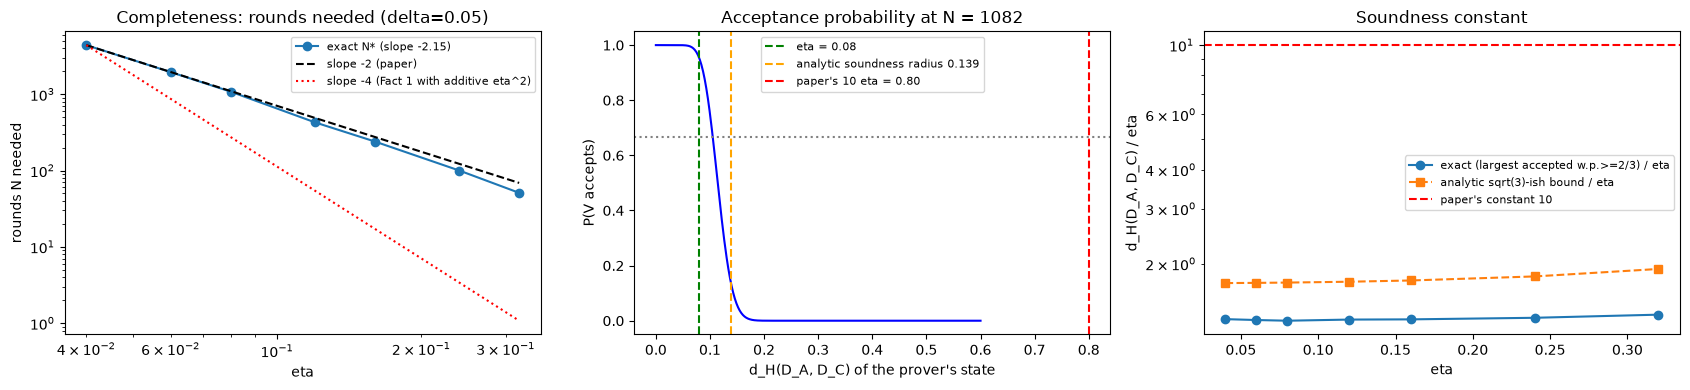

[V5] REPRODUCED: exact completeness >= 0.95 reached with N* eta^2/ln(1/delta) between 1.7 and 2.4; fitted exponent -2.15 (paper -2)
[V6] REPRODUCED: exact threshold is 1.31 to 1.37 x eta (analytic 1.73 to 1.92 x eta); never above 10 eta


In [19]:
# ---------------- V5: completeness and the scaling N = O(eta^-2 log(1/delta)); V6: soundness constant ----------------
t = time.time()
rows = []
for eta_ in ETA_GRID:
    Ns = n_star(eta_, DELTA)
    lo_, hi_ = eta_, 0.999                                                                # largest d_H(D_A, D_C) still accepted w.p. >= 2/3 at N = N*
    for _ in range(40):
        mid = 0.5 * (lo_ + hi_)
        if accept_prob(Ns, float(f_acc(mid)), eta_) >= 2 / 3: lo_ = mid
        else: hi_ = mid
    rows.append([eta_, Ns, Ns * eta_ ** 2 / math.log(1 / DELTA), math.ceil(2 * eta_ ** -4 * math.log(2 / DELTA)), accept_prob(Ns, float(f_acc(eta_)), eta_),
                 lo_, lo_ / eta_, x_sound(eta_) / eta_])
sc_df = pd.DataFrame(rows, columns=["eta", "N* (completeness>=1-delta)", "N* eta^2 / ln(1/delta)", "N from Fact 1 (eta^-4)", "completeness at N*",
                                    "largest d_H accepted w.p.>=2/3", "ratio to eta", "analytic sqrt(1-sqrt(1-6eta^2))/eta"])
print(sc_df.to_string(index=False, float_format=lambda v: f"{v:.4g}")); print(f"({time.time()-t:.1f}s)")
slope = np.polyfit(np.log(sc_df["eta"]), np.log(sc_df["N* (completeness>=1-delta)"]), 1)[0]
print(f"fitted exponent of N* in eta: {slope:.3f}   (paper: -2;  what Fact 1 alone would give: -4)")
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].loglog(sc_df["eta"], sc_df["N* (completeness>=1-delta)"], "o-", label=f"exact N* (slope {slope:.2f})")
e_ = sc_df["eta"].values; ax[0].loglog(e_, sc_df["N* (completeness>=1-delta)"].iloc[0] * (e_ / e_[0]) ** -2.0, "k--", label="slope -2 (paper)")
ax[0].loglog(e_, sc_df["N* (completeness>=1-delta)"].iloc[0] * (e_ / e_[0]) ** -4.0, "r:", label="slope -4 (Fact 1 with additive eta^2)")
ax[0].set_xlabel("eta"); ax[0].set_ylabel("rounds N needed"); ax[0].legend(fontsize=8); ax[0].set_title(f"Completeness: rounds needed (delta={DELTA})")
N_demo = n_star(ETA, DELTA)
dd = np.linspace(0, 0.6, 400); pa = [accept_prob(N_demo, float(f_acc(d_)), ETA) for d_ in dd]
ax[1].plot(dd, pa, "b-"); ax[1].axhline(2 / 3, c="gray", ls=":"); ax[1].axvline(ETA, c="g", ls="--", label=f"eta = {ETA}")
ax[1].axvline(x_sound(ETA), c="orange", ls="--", label=f"analytic soundness radius {x_sound(ETA):.3f}"); ax[1].axvline(10 * ETA, c="r", ls="--", label=f"paper's 10 eta = {10*ETA:.2f}")
ax[1].set_xlabel("d_H(D_A, D_C) of the prover's state"); ax[1].set_ylabel("P(V accepts)"); ax[1].set_title(f"Acceptance probability at N = {N_demo}"); ax[1].legend(fontsize=8)
ax[2].plot(sc_df["eta"], sc_df["ratio to eta"], "o-", label="exact (largest accepted w.p.>=2/3) / eta"); ax[2].plot(sc_df["eta"], sc_df["analytic sqrt(1-sqrt(1-6eta^2))/eta"], "s--", label="analytic sqrt(3)-ish bound / eta")
ax[2].axhline(10, c="r", ls="--", label="paper's constant 10"); ax[2].set_yscale("log"); ax[2].set_xlabel("eta"); ax[2].set_ylabel("d_H(D_A, D_C) / eta"); ax[2].legend(fontsize=8); ax[2].set_title("Soundness constant")
plt.tight_layout(); plt.show()
verdict("V5", "Theorem 2 completeness: accepted w.p. 1-delta with N = O(eta^-2 log(1/delta))", "N = O(K eta^-2 log(1/delta))",
        f"exact completeness >= {1-DELTA} reached with N* eta^2/ln(1/delta) between {sc_df['N* eta^2 / ln(1/delta)'].min():.1f} and {sc_df['N* eta^2 / ln(1/delta)'].max():.1f}; fitted exponent {slope:.2f} (paper -2)",
        "reproduced" if abs(slope + 2) < 0.2 and (sc_df["completeness at N*"] >= 1 - DELTA - 1e-9).all() else "not reached")
verdict("V6", "Theorem 2 soundness: accepted w.p. >= 2/3 implies d_H(D_C, D_A) <= 10 eta", "<= 10 eta (proof), O(eta)",
        f"exact threshold is {sc_df['ratio to eta'].min():.2f} to {sc_df['ratio to eta'].max():.2f} x eta (analytic {sc_df.iloc[:, -1].min():.2f} to {sc_df.iloc[:, -1].max():.2f} x eta); never above 10 eta",
        "reproduced" if (sc_df["ratio to eta"] <= 10).all() else "not reached")

In [20]:
# ---------------- the protocol, end to end, with the real circuit (Figure 4 and Figure 5) ----------------
P_CACHE = {}
def p_circuit_cached(DA_, G_, n):
    key = (id(G_), np.asarray(DA_, dtype=float).tobytes())
    if key not in P_CACHE: P_CACHE[key] = p_out1(DA_, G_, n)       # the Qiskit statevector evolution is done once per distinct prover state
    return P_CACHE[key]

def run_protocol(prover, N, eta, G_, n, rg):
    """One run of Figure 4/5.  prover = list of (weight, D_A): each round P draws which state to send (a single entry = the i.i.d. prover).
    Round type 0: V measures the n qubits in the Z basis (sample x ~ D_A).  Round type 1: V runs the Qiskit circuit G and records the out bit
    (Bernoulli with the circuit's exact P(out=1)).  V accepts iff the mean of the out bits >= 1 - 2 eta^2; it returns the samples S."""
    w = np.array([a for a, _ in prover], dtype=float); w = w / w.sum()
    pc = np.array([p_circuit_cached(DA_, G_, n) for _, DA_ in prover])
    typ = rg.integers(0, 2, N); which = rg.choice(len(prover), size=N, p=w)
    S = []; ones = 0; n1 = 0
    for j, (_, DA_) in enumerate(prover):
        m1 = int(((typ == 1) & (which == j)).sum()); m0 = int(((typ == 0) & (which == j)).sum())
        ones += int(rg.binomial(m1, pc[j])); n1 += m1
        if m0: S.append(rg.choice(NSTR, size=m0, p=DA_ / DA_.sum()))
    S = np.concatenate(S) if S else np.array([], dtype=int)
    p_hat = ones / max(n1, 1)
    return p_hat >= 1 - 2 * eta ** 2, S, p_hat, n1

N_RUN = n_star(ETA, DELTA)
print(f"eta = {ETA}, delta = {DELTA}: N = {N_RUN} rounds;  honest prover forwards |psi_D_test>")
rg_run = np.random.default_rng(SEED + 4)
acc, S, p_hat, n1 = run_protocol([(1.0, D_test)], N_RUN, ETA, G, NQ, rg_run)
emp = np.bincount(S, minlength=NSTR) / len(S)
print(f"  one run: accepted = {acc}, p_hat = {p_hat:.4f} (threshold {1-2*ETA**2:.4f}), |S| = {len(S)}, n_1 = {n1}, d_H(empirical S, D_test) = {hell(emp, D_test):.4f}, TV = {tvd(emp, D_test):.4f}")
# Monte-Carlo estimate of completeness vs the exact value
wins = 0; trials_ = MC_TRIALS // 4
for _ in range(trials_):
    wins += run_protocol([(1.0, D_test)], N_RUN, ETA, G, NQ, rg_run)[0]
p_exact = accept_prob(N_RUN, float(f_acc(hell(D_test, D_C))), ETA)
print(f"  completeness: Monte-Carlo {wins/trials_:.4f} over {trials_} runs, exact binomial sum {p_exact:.4f}  (eta_test = {eta_test:.4f} <= eta = {ETA})")
verdict("V5b", "Theorem 2 completeness, end to end on the real circuit and real data", "1 - delta", f"Monte-Carlo {wins/trials_:.4f}, exact {p_exact:.4f}, required {1-DELTA}; |S| = {len(S)} samples returned, d_H(S, D) = {hell(emp, D_test):.3f}",
        "reproduced" if wins / trials_ >= 1 - DELTA - 0.02 and abs(wins / trials_ - p_exact) < 0.02 else "not reached")

eta = 0.08, delta = 0.05: N = 1082 rounds;  honest prover forwards |psi_D_test>


  one run: accepted = True, p_hat = 0.9944 (threshold 0.9872), |S| = 550, n_1 = 532, d_H(empirical S, D_test) = 0.0544, TV = 0.0549


  completeness: Monte-Carlo 0.9860 over 10000 runs, exact binomial sum 0.9853  (eta_test = 0.0708 <= eta = 0.08)
[V5b] REPRODUCED: Monte-Carlo 0.9860, exact 0.9853, required 0.95; |S| = 550 samples returned, d_H(S, D) = 0.054


## 7. Mixtures, non-i.i.d. and mixed-state provers: Lemma 3 and Theorems 3 and 4 (claims V7 to V10)

**Lemma 3.** If `sum_i q_i f(d_H(D_C, D_Ai)) >= 1 - 50 eta^2` then `d_H(sum_i q_i D_Ai, D_C) <= O(eta^{1/4})`. We test it on random and on optimised adversarial mixtures.
*A sharper statement (derived here, checked numerically):* since `f(x) = 1 - x^2 + x^4/2 <= 1 - x^2/2` on `[0,1]` and `d_H^2` is jointly convex, `d_H^2(sum q_i D_Ai, D_C) <= sum q_i d_H^2(D_Ai, D_C) <= 2 (1 - sum q_i f) <= 100 eta^2`, i.e. **`d_H <= 10 eta`** (linear, not `eta^{1/4}`).
The proof of Lemma 3 also uses the step "`d_H(P,Q) >= sqrt(2) TV(P,Q)`", which contradicts the inequality `TV <= sqrt(2) d_H` stated in Section 2; we test that step too (claim V8).

30000 of 30000 random mixtures satisfy the hypothesis with some eta <= 0.1
random mixtures: max d_H(mix, D_C)/eta = 8.851 (proof of the sharper bound: <= 10),  max d_H(mix, D_C)/eta^(1/4) = 1.528


 eta  worst d_H(mix, D_C) found  ratio to eta  single-component value / eta  proved bound / eta  eta^(1/4)
0.02                     0.1421        7.1070                        7.1071                10.0     0.3761
0.05                     0.3660        7.3205                        7.3205                10.0     0.4729
0.08                     0.6325        7.9057                        7.9057                10.0     0.5318
(1179.9s)


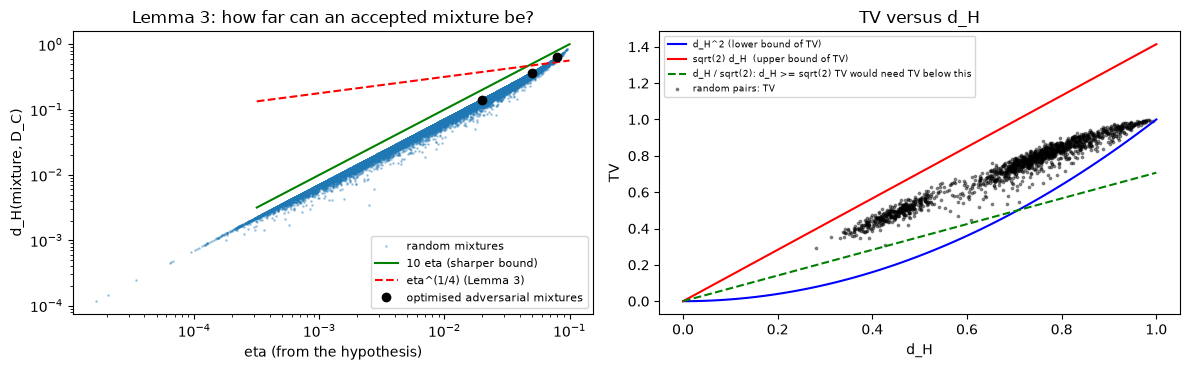

Lemma 3's proof step d_H >= sqrt(2) TV fails for 5000 of 5000 random pairs (it would need d_H >= sqrt(2) TV; the printed Section 2 inequality says TV <= sqrt(2) d_H, i.e. d_H >= TV/sqrt(2)). Largest sqrt(2) TV / d_H = 1.747
[V7] REPRODUCED: holds; random mixtures max d_H/eta = 8.85, optimised adversarial mixtures max d_H/eta = 7.91; a linear bound 10 eta is proved and checked
[V8] NOT REACHED: false for 5000/5000 random pairs (the correct direction TV <= sqrt(2) d_H of Section 2 still gives the lemma's conclusion)


In [21]:
# ---------------- V7 / V8: Lemma 3 ----------------
rs5 = np.random.default_rng(SEED + 5)
def rand_component(DC_, rg):
    """A distribution at a random Hellinger distance (log-uniform from 1e-3 to 1) from DC_."""
    alpha = np.exp(rg.uniform(np.log(1e-4), 0)); other = rg.dirichlet(np.ones(len(DC_)) * rg.choice([0.1, 0.5, 1.0]))
    return (1 - alpha) * DC_ + alpha * other
ratio_q = []; pts = []
for _ in range(N_MIXTURES):
    k_ = int(rs5.integers(1, 6)); comps = [rand_component(D_C, rs5) for _ in range(k_)]; q_ = rs5.dirichlet(np.ones(k_) * rs5.choice([0.2, 1, 5]))
    S_ = float(sum(qi * f_acc(hell(D_C, Di)) for qi, Di in zip(q_, comps)))
    if S_ >= 1 - 50 * 0.1 ** 2 and S_ < 1 - 1e-12:
        eta_eff = math.sqrt((1 - S_) / 50); mix = sum(qi * Di for qi, Di in zip(q_, comps)); pts.append((eta_eff, hell(mix, D_C)))
pts = np.array(pts); print(f"{len(pts)} of {N_MIXTURES} random mixtures satisfy the hypothesis with some eta <= 0.1")
r_lin = (pts[:, 1] / pts[:, 0]).max(); r_paper = (pts[:, 1] / pts[:, 0] ** 0.25).max()
print(f"random mixtures: max d_H(mix, D_C)/eta = {r_lin:.3f} (proof of the sharper bound: <= 10),  max d_H(mix, D_C)/eta^(1/4) = {r_paper:.3f}")

# adversarial mixtures: maximise d_H(mix, D_C) subject to sum q_i f(d_H(D_C, D_Ai)) >= 1 - 50 eta^2, 3 components, SLSQP from random starts
def adv_mixture(eta_, rg, ncomp=3):
    """component i = (1 - a_i) D_C + a_i E_i with free E_i (softmax) and free mixing weight a_i (sigmoid); weights q_i (softmax); SLSQP from a feasible start"""
    K_ = NSTR
    def unpack(v):
        E = np.exp(v[:ncomp * K_].reshape(ncomp, K_)); E = E / E.sum(1, keepdims=True)
        al = 1 / (1 + np.exp(-v[ncomp * K_:ncomp * K_ + ncomp])); A = (1 - al)[:, None] * D_C[None, :] + al[:, None] * E
        z = v[ncomp * K_ + ncomp:]; q = np.exp(z - z.max()); return A, q / q.sum()
    obj = lambda v: -hell((lambda A, q: q @ A)(*unpack(v)), D_C)
    con = lambda v: (lambda A, q: float(sum(q[i] * f_acc(hell(D_C, A[i])) for i in range(ncomp))) - (1 - 50 * eta_ ** 2))(*unpack(v))
    bestv = 0.0
    for s_ in range(N_OPT_STARTS):
        v0 = np.concatenate([3.0 * rg.normal(size=ncomp * K_), -6.0 + rg.normal(size=ncomp), rg.normal(size=ncomp)])      # start: tiny far parts, i.e. feasible
        r_ = minimize(obj, v0, constraints=[{"type": "ineq", "fun": con}], method="SLSQP", options=dict(maxiter=200))
        if con(r_.x) >= -1e-7: bestv = max(bestv, -r_.fun)
    return bestv
t = time.time(); adv_rows = []
for eta_ in (0.02, 0.05, 0.08):
    best_ = adv_mixture(eta_, rs5)
    single = math.sqrt(1 - math.sqrt(1 - 100 * eta_ ** 2))                                   # one component sitting exactly on the constraint
    adv_rows.append([eta_, best_, best_ / eta_, single / eta_, 10.0, eta_ ** 0.25])
adv_df = pd.DataFrame(adv_rows, columns=["eta", "worst d_H(mix, D_C) found", "ratio to eta", "single-component value / eta", "proved bound / eta", "eta^(1/4)"])
print(adv_df.round(4).to_string(index=False)); print(f"({time.time()-t:.1f}s)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].loglog(pts[:, 0], pts[:, 1], ".", ms=2, alpha=.3, label="random mixtures"); ee = np.logspace(-3.5, -1, 50)
ax[0].loglog(ee, 10 * ee, "g-", label="10 eta (sharper bound)"); ax[0].loglog(ee, ee ** 0.25, "r--", label="eta^(1/4) (Lemma 3)"); ax[0].loglog(adv_df["eta"], adv_df["worst d_H(mix, D_C) found"], "ko", label="optimised adversarial mixtures")
ax[0].set_xlabel("eta (from the hypothesis)"); ax[0].set_ylabel("d_H(mixture, D_C)"); ax[0].legend(fontsize=8); ax[0].set_title("Lemma 3: how far can an accepted mixture be?")
rs6 = np.random.default_rng(SEED + 6); cnt_viol = 0; tot_ = 0; worst_r = 0
for _ in range(5000):
    P_ = rs6.dirichlet(np.ones(NSTR)); Q_ = rs6.dirichlet(np.ones(NSTR) * rs6.choice([0.2, 1])); h_ = hell(P_, Q_); tv_ = tvd(P_, Q_); tot_ += 1
    cnt_viol += h_ < np.sqrt(2) * tv_; worst_r = max(worst_r, np.sqrt(2) * tv_ / h_)
xs_ = np.linspace(0, 1, 100); ax[1].plot(xs_, xs_ ** 2, "b-", label="d_H^2 (lower bound of TV)"); ax[1].plot(xs_, np.sqrt(2) * xs_, "r-", label="sqrt(2) d_H  (upper bound of TV)")
ax[1].plot(xs_, xs_ / np.sqrt(2), "g--", label="d_H / sqrt(2): d_H >= sqrt(2) TV would need TV below this")
tvs = []; hs = []
for _ in range(1500):
    P_ = rs6.dirichlet(np.ones(NSTR) * rs6.choice([0.1, 1])); Q_ = rs6.dirichlet(np.ones(NSTR) * rs6.choice([0.1, 1])); hs.append(hell(P_, Q_)); tvs.append(tvd(P_, Q_))
ax[1].scatter(hs, tvs, s=3, alpha=.4, c="k", label="random pairs: TV"); ax[1].set_xlabel("d_H"); ax[1].set_ylabel("TV"); ax[1].legend(fontsize=6.5); ax[1].set_title("TV versus d_H")
plt.tight_layout(); plt.show()
print(f"Lemma 3's proof step d_H >= sqrt(2) TV fails for {cnt_viol} of {tot_} random pairs (it would need d_H >= sqrt(2) TV; the printed Section 2 inequality says TV <= sqrt(2) d_H, i.e. d_H >= TV/sqrt(2)). Largest sqrt(2) TV / d_H = {worst_r:.3f}")
ok7 = (adv_df["ratio to eta"] <= 10).all() and r_lin <= 10
verdict("V7", "Lemma 3 / Theorems 3, 4: d_H(sum q_i D_Ai, D_C) <= O(eta^{1/4})", "O(eta^{1/4})", f"holds; random mixtures max d_H/eta = {r_lin:.2f}, optimised adversarial mixtures max d_H/eta = {adv_df['ratio to eta'].max():.2f}; a linear bound 10 eta is proved and checked",
        "reproduced" if ok7 else "not reached")
verdict("V8", "Lemma 3 proof step: d_H(P,Q) >= sqrt(2) TV(P,Q)", "used in eq. (4)", f"false for {cnt_viol}/{tot_} random pairs (the correct direction TV <= sqrt(2) d_H of Section 2 still gives the lemma's conclusion)", "not reached" if cnt_viol > 0 else "reproduced")

In [22]:
# ---------------- V9: Theorem 3 (non-i.i.d. prover, Figure 5) ----------------
D_atk = pushforward(D_test, 1)                       # a "bad" state: every input moved by the Hamming-1 adversary
pg = float(f_acc(hell(D_test, D_C))); pb = float(f_acc(hell(D_atk, D_C)))
print(f"good state |psi_D_test>: P(out=1) = {pg:.4f};  bad state (Hamming-1 attacked inputs): d_H to D_C = {hell(D_atk, D_C):.3f}, P(out=1) = {pb:.4f}")
bs = np.array([0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]); rows = []
Npar = n_star(ETA, DELTA / 2)
for b_ in bs:
    D_avg = (1 - b_) * D_test + b_ * D_atk; p_mix = (1 - b_) * pg + b_ * pb
    rows.append([b_, accept_prob(Npar, p_mix, ETA), hell(D_avg, D_C), hell(D_avg, D_test), float(D_avg[err].sum())])
t9 = pd.DataFrame(rows, columns=["fraction b of bad states", "P(V accepts)", "d_H(D_avg, D_C)", "d_H(D_avg, D)", "risk of f under D_avg"])
print(f"N = {Npar} rounds (completeness >= 1 - delta/2)"); print(t9.round(4).to_string(index=False))
# Monte-Carlo with the real protocol (a prover alternating randomly between the two states) and the single returned sample
rg9 = np.random.default_rng(SEED + 9); mc_rows = []
for b_ in (0.0, 0.02, 0.05, 0.2):
    acc_n = 0; pick = []; T9 = max(1000, MC_TRIALS // 4)
    for _ in range(T9):
        a_, S_, ph_, n1_ = run_protocol([(1 - b_, D_test), (b_, D_atk)] if b_ > 0 else [(1.0, D_test)], Npar, ETA, G, NQ, rg9)
        if a_: acc_n += 1; pick.append(S_[rg9.integers(len(S_))])
    mc_rows.append([b_, acc_n / T9, accept_prob(Npar, (1 - b_) * pg + b_ * pb, ETA), (np.mean(err[np.array(pick)]) if pick else np.nan), float(((1 - b_) * D_test + b_ * D_atk)[err].sum())])
mc9 = pd.DataFrame(mc_rows, columns=["b", "accept rate (MC)", "accept prob (exact)", "risk of the returned sample (MC)", "risk under D_avg (exact)"])
print(mc9.round(4).to_string(index=False))
b_ok = bs[t9["P(V accepts)"].values >= 0.5]; D_edge = (1 - b_ok.max()) * D_test + b_ok.max() * D_atk
print(f"largest bad fraction still accepted w.p. >= 1/2: b = {b_ok.max()}: d_H(D_avg, D_C) = {hell(D_edge, D_C):.4f} = {hell(D_edge, D_C)/ETA:.2f} eta  (Theorem 3: O(eta^1/4); the sharper bound: <= 10 eta). "
      f"The honest prover itself is accepted w.p. {t9['P(V accepts)'].iloc[0]:.3f} at this N, so a prover that sends bad states cannot be accepted w.p. 1 - delta/2.")
verdict("V9", "Theorem 3: non-i.i.d. prover, one random sample, d_H(D_C, D_A) <= O(eta^{1/4})", "O(eta^{1/4})", f"Monte-Carlo of Figure 5 matches the exact acceptance (max gap {np.abs(mc9['accept rate (MC)'] - mc9['accept prob (exact)']).max():.3f}); mixtures accepted w.p. >= 1/2 have d_H(D_avg, D_C) <= {hell(D_edge, D_C)/ETA:.2f} eta; risk of the returned sample tracks the exact mixture risk",
        "reproduced" if np.abs(mc9["accept rate (MC)"] - mc9["accept prob (exact)"]).max() < 0.05 and hell(D_edge, D_C) <= 10 * ETA else "not reached")

good state |psi_D_test>: P(out=1) = 0.9950;  bad state (Hamming-1 attacked inputs): d_H to D_C = 0.587, P(out=1) = 0.7148


N = 1451 rounds (completeness >= 1 - delta/2)


 fraction b of bad states  P(V accepts)  d_H(D_avg, D_C)  d_H(D_avg, D)  risk of f under D_avg
                    0.000        0.9951           0.0708         0.0000                 0.1527
                    0.005        0.9769           0.0710         0.0109                 0.1551
                    0.010        0.9320           0.0714         0.0159                 0.1575
                    0.020        0.7410           0.0726         0.0235                 0.1624
                    0.050        0.1110           0.0783         0.0416                 0.1768
                    0.100        0.0003           0.0920         0.0674                 0.2009
                    0.200        0.0000           0.1270         0.1139                 0.2491
                    0.500        0.0000           0.2461         0.2429                 0.3936
                    1.000        0.0000           0.5870         0.5846                 0.6346


   b  accept rate (MC)  accept prob (exact)  risk of the returned sample (MC)  risk under D_avg (exact)
0.00            0.9934               0.9951                            0.1494                    0.1527
0.02            0.7407               0.7410                            0.1670                    0.1624
0.05            0.1142               0.1110                            0.1786                    0.1768
0.20            0.0000               0.0000                               NaN                    0.2491
largest bad fraction still accepted w.p. >= 1/2: b = 0.02: d_H(D_avg, D_C) = 0.0726 = 0.91 eta  (Theorem 3: O(eta^1/4); the sharper bound: <= 10 eta). The honest prover itself is accepted w.p. 0.995 at this N, so a prover that sends bad states cannot be accepted w.p. 1 - delta/2.
[V9] REPRODUCED: Monte-Carlo of Figure 5 matches the exact acceptance (max gap 0.003); mixtures accepted w.p. >= 1/2 have d_H(D_avg, D_C) <= 0.91 eta; risk of the returned sample tracks the exact mix

In [23]:
# ---------------- V10: Theorem 4 (mixed states): P(out=1) is the q-average of f(d_H(D_C, D_Ai)) ----------------
# n = 3 with explicit DensityMatrix evolution through the circuit, then n = 5 with a purification (environment qubit)
rs10 = np.random.default_rng(SEED + 10); n3 = 3
DCm = rs10.dirichlet(np.ones(2 ** n3)); Cm = QuantumCircuit(n3); Cm.append(StatePreparation(np.sqrt(DCm)), range(n3)); Gm = comparison_circuit(Cm, n3)
D1, D2 = rs10.dirichlet(np.ones(2 ** n3)), rs10.dirichlet(np.ones(2 ** n3) * .3); qm = 0.7
rho_A = qm * np.outer(np.sqrt(D1), np.sqrt(D1)) + (1 - qm) * np.outer(np.sqrt(D2), np.sqrt(D2))
e0 = np.zeros((2, 2)); e0[0, 0] = 1; a0 = np.zeros((2 ** n3, 2 ** n3)); a0[0, 0] = 1
rho_full = np.kron(a0, np.kron(rho_A, e0))                                     # |0><0|_aux (x) rho_adv (x) |0><0|_out   (aux most significant)
out1 = float(DensityMatrix(rho_full).evolve(Gm).probabilities([0])[1])
pred = qm * float(f_acc(hell(D1, DCm))) + (1 - qm) * float(f_acc(hell(D2, DCm)))
print(f"n=3, DensityMatrix through G: P(out=1) = {out1:.12f};  sum_i q_i f(d_H(D_C, D_Ai)) = {pred:.12f}  (difference {abs(out1-pred):.1e})")
Zdist = np.real(np.diag(rho_A)); print(f"Z-basis samples of the mixed state follow sum q_i D_i: max difference {np.abs(Zdist - (qm*D1 + (1-qm)*D2)).max():.1e}")
# n = 5: environment qubit purifies the mixture of |psi_D_test> and the Hamming-1 attacked state
Dm2 = pushforward(D_test, 1); env_state = lambda i: np.eye(2)[i]
glob = sum(np.sqrt(w_) * np.kron(env_state(i), np.kron(np.eye(2 ** NQ)[0], np.kron(np.sqrt(Di), np.array([1.0, 0.0])))) for i, (w_, Di) in enumerate([(qm, D_test), (1 - qm, Dm2)]))
Gext = QuantumCircuit(2 * NQ + 2); Gext.compose(G, qubits=list(range(2 * NQ + 1)), inplace=True)
out1_5 = float(Statevector(glob).evolve(Gext).probabilities([0])[1])
pred5 = qm * float(f_acc(hell(D_test, D_C))) + (1 - qm) * float(f_acc(hell(Dm2, D_C)))
print(f"n=5 (12 qubits incl. the environment qubit): P(out=1) = {out1_5:.12f};  q-average of f = {pred5:.12f}  (difference {abs(out1_5-pred5):.1e})")
verdict("V10", "Theorem 4 / its proof: for mixed states P(out=1) = sum_i q_i f(d_H(D_C, D_Ai))", "linearity in rho", f"DensityMatrix n=3: error {abs(out1-pred):.1e}; purified n=5: error {abs(out1_5-pred5):.1e}", "reproduced" if max(abs(out1 - pred), abs(out1_5 - pred5)) < 1e-9 else "not reached")

n=3, DensityMatrix through G: P(out=1) = 0.770088254174;  sum_i q_i f(d_H(D_C, D_Ai)) = 0.770088254174  (difference 5.1e-15)
Z-basis samples of the mixed state follow sum q_i D_i: max difference 2.8e-17


n=5 (12 qubits incl. the environment qubit): P(out=1) = 0.910945151227;  q-average of f = 0.910945151227  (difference 2.7e-15)
[V10] REPRODUCED: DensityMatrix n=3: error 5.1e-15; purified n=5: error 2.7e-15


## 8. The constant-memory verifier: history state, Lemma 4 and Corollary 2 (claims V11 to V14)

In Section 4.2 `V` cannot run `G`; `P` must send the **history state** `|phi> = (T'+1)^{-1/2} sum_j |j>_clock G_j ... G_1 |0>_out |psi_DA>_adv |0^n>_aux`, and `V` checks it with the local Hamiltonian
`H_G = H_in + H_prop (+ H_clock)`: `H_in = |0><0|_clock (x) sum_{j in out,aux} Pi_j^(1)` and `H_prop = sum_j [ -1/2 |j><j-1| (x) G_j - 1/2 |j-1><j| (x) G_j^dagger + 1/2(|j><j| + |j-1><j-1|) (x) I ]`.
We build these matrices **exactly** for the toy circuit `G_toy` of the circuit section (`n = 2`, `T' = 10` gates, binary clock of dimension 11, total dimension 352) from the very gate list that is drawn, and test:

* **(a)** the history state of every `|psi_DA>` has energy 0 and the ground space of `H_in + H_prop` is exactly `2^n`-dimensional; the Z measurement of the history state gives the clock marginal `1/(T'+1)`, the distribution `D_A` on `adv` when clock, out, aux are 0, and `out ~ Bernoulli(f(d_H))` when the clock is `T'`;
* **(b)** Lemma 4's quantitative statement: *every* state with `<phi|H_G|phi> <= epsilon/T'` has clock probabilities within `(1 +- 5 epsilon)/(T'+1)`. This is a linear program over states in disguise: for a given energy budget the extreme value of a diagonal observable is found **exactly** by a Lagrange-dual sweep (the set of `(<H>, <A>)` pairs is convex), so the test uses the *worst* state, not random ones;
* **(c)** Corollary 2: budget `eta^2/T'^3` gives probabilities within `(1 +- 7 eta)/(T'+1)`.

The energy budget in Lemma 4 is garbled in the PDF text layer; we read it as `epsilon/T'` because Corollary 2 applies the lemma with `epsilon = eta^2/T'^2` to states with `Tr(H rho) <= eta^2/T'^3 = epsilon/T'`. For transparency (b) is also evaluated with budgets `epsilon/T'^2` and `epsilon/T'^3`.

In [24]:
# ---------------- exact Hamiltonian of the toy circuit ----------------
nq_t = G_toy.num_qubits; dim_t = 2 ** nq_t; TPt = TP_toy; nT = HIST_N
def gate_matrix(inst):
    qc_ = QuantumCircuit(nq_t); qc_.append(inst.operation, [G_toy.find_bit(q).index for q in inst.qubits]); return Operator(qc_).data
GATES = [gate_matrix(i) for i in G_toy.data]
s_idx = np.arange(dim_t); out_bit = s_idx & 1; adv_val = (s_idx >> 1) & (2 ** nT - 1); aux_val = (s_idx >> (nT + 1)) & (2 ** nT - 1)
pen = out_bit + np.array([bin(a).count("1") for a in aux_val])                          # number of out/aux qubits that are 1
DIMH = (TPt + 1) * dim_t
H_in = np.zeros((DIMH, DIMH), dtype=complex); H_in[np.arange(dim_t), np.arange(dim_t)] = pen            # clock = 0 block
H_prop = np.zeros((DIMH, DIMH), dtype=complex)
blk = lambda a, b: (slice(a * dim_t, (a + 1) * dim_t), slice(b * dim_t, (b + 1) * dim_t))
for j in range(1, TPt + 1):
    Gj = GATES[j - 1]
    H_prop[blk(j, j - 1)] += -0.5 * Gj; H_prop[blk(j - 1, j)] += -0.5 * Gj.conj().T
    H_prop[blk(j, j)] += 0.5 * np.eye(dim_t); H_prop[blk(j - 1, j - 1)] += 0.5 * np.eye(dim_t)
H_G = H_in + H_prop
assert np.abs(H_G - H_G.conj().T).max() < 1e-12
w_all = np.linalg.eigvalsh(H_G)
n_zero = int((w_all < 1e-9).sum()); gap = float(w_all[n_zero])
print(f"H_G (toy, n={nT}, T'={TPt}): dimension {DIMH};  zero eigenvalues: {n_zero} (expected 2^n = {2**nT});  next eigenvalue (gap) = {gap:.5f}")
DC_toy = np.abs(Statevector(C_toy).data) ** 2
rh = np.random.default_rng(SEED + 11); rows = []
for t_ in range(6):
    DA_ = rh.dirichlet(np.ones(2 ** nT) * rh.choice([0.3, 1.0, 3.0])); psi = np.sqrt(DA_)
    cur = np.kron(np.eye(2 ** nT)[0], np.kron(psi, np.array([1.0, 0.0]))).astype(complex); hist_ = [cur]
    for Gj in GATES: cur = Gj @ cur; hist_.append(cur)
    phi = np.concatenate(hist_) / math.sqrt(TPt + 1)
    E_ = float(np.real(np.vdot(phi, H_G @ phi)))
    P = (np.abs(phi) ** 2).reshape(TPt + 1, dim_t)                                          # P[j, s]: Z-basis probabilities
    clock = P.sum(1)
    m0 = (out_bit == 0) & (aux_val == 0); D_adv = np.zeros(2 ** nT)
    for s_ in np.where(m0)[0]: D_adv[adv_val[s_]] += P[0, s_]
    D_adv /= D_adv.sum()
    p_last = P[TPt][out_bit == 1].sum() / P[TPt].sum()
    rows.append([E_, np.abs(clock - 1 / (TPt + 1)).max(), np.abs(D_adv - DA_).max(), p_last, float(f_acc(hell(DA_, DC_toy))), p_out1(DA_, G_toy, nT)])
ht = pd.DataFrame(rows, columns=["<phi|H|phi>", "max |P(clock=j) - 1/(T'+1)|", "max |D_adv - D_A| (clock 0, out/aux 0)", "P(out=1 | clock=T')", "f(d_H(D_A,D_C))", "P(out=1) of G_toy"])
print(ht.to_string(index=False, float_format=lambda v: f"{v:.3e}" if abs(v) < 1e-3 else f"{v:.6f}"))
ok11 = (n_zero == 2 ** nT) and ht.iloc[:, 0].abs().max() < 1e-12 and ht.iloc[:, 1].max() < 1e-12 and ht.iloc[:, 2].max() < 1e-12 and (ht.iloc[:, 3] - ht.iloc[:, 4]).abs().max() < 1e-9 and (ht.iloc[:, 3] - ht.iloc[:, 5]).abs().max() < 1e-9
verdict("V11", "Lemma 4(a) / Section 4.2: history state is a zero-energy state; clock marginal 1/(T'+1); D_A at clock 0; out ~ Bernoulli(f) at clock T'", "structural claims", f"exact on the toy circuit: ground space dimension {n_zero} (=2^n), max energy {ht.iloc[:,0].abs().max():.1e}, max marginal error {ht.iloc[:,1].max():.1e}, max |p - f| = {(ht.iloc[:,3]-ht.iloc[:,4]).abs().max():.1e}", "reproduced" if ok11 else "not reached")

H_G (toy, n=2, T'=10): dimension 352;  zero eigenvalues: 4 (expected 2^n = 4);  next eigenvalue (gap) = 0.01018


 <phi|H|phi>  max |P(clock=j) - 1/(T'+1)|  max |D_adv - D_A| (clock 0, out/aux 0)  P(out=1 | clock=T')  f(d_H(D_A,D_C))  P(out=1) of G_toy
   1.408e-17                    5.551e-17                               2.776e-17             0.770868         0.770868           0.770868
   1.425e-17                    4.163e-17                               5.551e-17             0.752674         0.752674           0.752674
   7.366e-18                    2.776e-17                               1.388e-17             0.834693         0.834693           0.834693
   1.275e-17                    4.163e-17                               1.110e-16             0.958136         0.958136           0.958136
   1.065e-17                    2.776e-17                               2.776e-17             0.815939         0.815939           0.815939
   1.881e-17                    1.388e-17                               1.665e-16             0.872928         0.872928           0.872928
[V11] REPRODUCED: exact on 

H_G is real symmetric: True


 epsilon  energy budget eps/T'  claimed bound 5*eps  exact worst relative deviation  violated
   0.002                0.0002                 0.01                          0.2466      True
   0.005                0.0005                0.025                          0.3984      True
    0.01                 0.001                 0.05                          0.5763      True
    0.02                 0.002                  0.1                           0.839      True
    0.05                 0.005                 0.25                           1.392      True
     0.1                  0.01                  0.5                           2.052      True
(90.1s)


 epsilon energy budget read as  claimed 5*eps  exact worst relative deviation  violated
    0.01                eps/T'           0.05                          0.5763      True
    0.01              eps/T'^2           0.05                          0.1723      True
    0.01              eps/T'^3           0.05                         0.05343      True


 eta  energy budget eta^2/T'^3  claimed bound 7*eta  exact worst relative deviation  violated
0.05                   2.5e-06                 0.35                         0.02659     False
 0.1                     1e-05                  0.7                         0.05343     False
 0.2                     4e-05                  1.4                          0.1079     False
 0.3                     9e-05                  2.1                          0.1633     False
(252.6s)


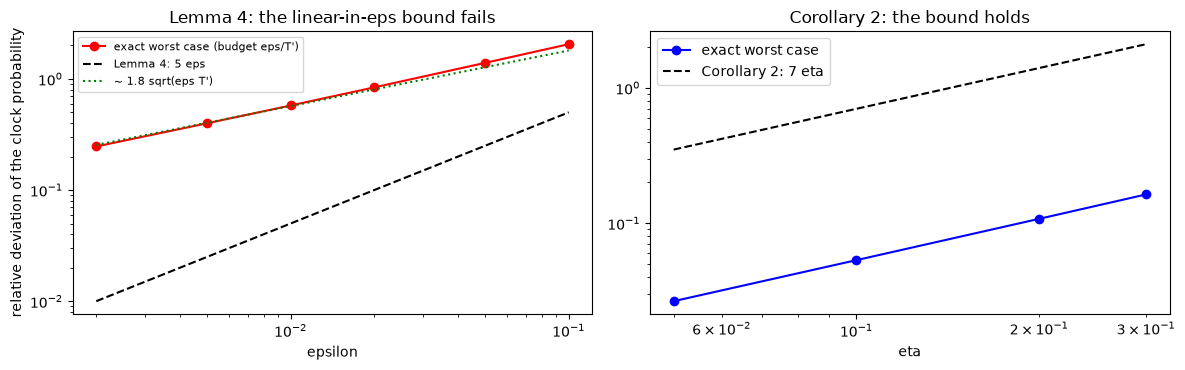

[V12] NOT REACHED: false: the exact worst state deviates by 0.247 at eps = 0.002 (claimed 0.010); violated for 6/6 values of eps, the deviation grows like sqrt(eps T')
[V13] REPRODUCED: holds: exact worst relative deviation 0.027 to 0.163 vs claimed 0.35 to 2.10


In [25]:
# ---------------- Lemma 4(b) and Corollary 2: exact extreme values under an energy budget ----------------
clock_of = np.repeat(np.arange(TPt + 1), dim_t); comp_of = np.tile(np.arange(dim_t), TPt + 1)
A0 = ((clock_of == 0) & (out_bit[comp_of] == 0) & (aux_val[comp_of] == 0)).astype(float)       # P(clock = 0, out = 0, aux = 0)
AT = (clock_of == TPt).astype(float)                                                            # P(clock = T')
base_prob = 1.0 / (TPt + 1)
H_use = H_G.real if np.abs(H_G.imag).max() < 1e-12 else H_G           # all gates of G_toy are real here, so a real symmetric eigensolver is exact and faster
print("H_G is real symmetric:", H_use is not H_G)
def extreme_state(Adiag, theta, sign, iters=24):
    """max over states with <H_G> <= theta of sign*<A> by a Lagrange-dual bisection (exact up to the bisection tolerance;
    the returned state always satisfies <H_G> <= theta, so it is a genuine witness)."""
    top = lambda mu: (lambda wv: wv[1][:, -1])(np.linalg.eigh(sign * np.diag(Adiag) - mu * H_use))
    lo, hi = np.log(1e-3), np.log(1e7); v_best = top(np.exp(hi))
    for _ in range(iters):
        mid = 0.5 * (lo + hi); v = top(np.exp(mid)); E = float(np.real(np.vdot(v, H_use @ v)))
        if E <= theta: hi = mid; v_best = v
        else: lo = mid
    return v_best, float(np.real(np.vdot(v_best, H_use @ v_best)))
def max_rel_dev(theta):
    """largest relative deviation (T'+1)|P - 1/(T'+1)| of the two clock events over ALL states of energy <= theta"""
    out_ = []
    for Ad in (A0, AT):
        best = 0.0
        for sg in (+1, -1):
            v, E = extreme_state(Ad, theta, sg); pr = float((Ad * np.abs(v) ** 2).sum()); best = max(best, abs(pr - base_prob) / base_prob)
        out_.append(best)
    return max(out_)
t = time.time(); rows = []
for eps in HIST_EPS:
    rows.append([eps, eps / TPt, 5 * eps, max_rel_dev(eps / TPt)])
l4 = pd.DataFrame(rows, columns=["epsilon", "energy budget eps/T'", "claimed bound 5*eps", "exact worst relative deviation"])
l4["violated"] = l4["exact worst relative deviation"] > l4["claimed bound 5*eps"] + 1e-9
print(l4.to_string(index=False, float_format=lambda v: f"{v:.4g}")); print(f"({time.time()-t:.1f}s)")
alt = []
for eps in (0.01,):
    for nm, th in (("eps/T'", eps / TPt), ("eps/T'^2", eps / TPt ** 2), ("eps/T'^3", eps / TPt ** 3)):
        alt.append([eps, nm, 5 * eps, max_rel_dev(th)])
l4b = pd.DataFrame(alt, columns=["epsilon", "energy budget read as", "claimed 5*eps", "exact worst relative deviation"]); l4b["violated"] = l4b.iloc[:, 3] > l4b.iloc[:, 2] + 1e-9
print(l4b.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
cor = []
for eta_ in (0.05, 0.1, 0.2, 0.3):
    cor.append([eta_, eta_ ** 2 / TPt ** 3, 7 * eta_, max_rel_dev(eta_ ** 2 / TPt ** 3)])
c2 = pd.DataFrame(cor, columns=["eta", "energy budget eta^2/T'^3", "claimed bound 7*eta", "exact worst relative deviation"]); c2["violated"] = c2.iloc[:, 3] > c2.iloc[:, 2] + 1e-9
print(c2.to_string(index=False, float_format=lambda v: f"{v:.4g}")); print(f"({time.time()-t:.1f}s)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].loglog(l4["epsilon"], l4["exact worst relative deviation"], "ro-", label="exact worst case (budget eps/T')"); ax[0].loglog(l4["epsilon"], l4["claimed bound 5*eps"], "k--", label="Lemma 4: 5 eps")
ee = np.array(HIST_EPS); ax[0].loglog(ee, 1.8 * np.sqrt(ee * TPt), "g:", label="~ 1.8 sqrt(eps T')")
ax[0].set_xlabel("epsilon"); ax[0].set_ylabel("relative deviation of the clock probability"); ax[0].legend(fontsize=8); ax[0].set_title("Lemma 4: the linear-in-eps bound fails")
ax[1].loglog(c2["eta"], c2["exact worst relative deviation"], "bo-", label="exact worst case"); ax[1].loglog(c2["eta"], c2["claimed bound 7*eta"], "k--", label="Corollary 2: 7 eta"); ax[1].set_xlabel("eta"); ax[1].legend(); ax[1].set_title("Corollary 2: the bound holds")
plt.tight_layout(); plt.show()
verdict("V12", "Lemma 4(b): states with <H_G> <= eps/T' have clock probabilities within (1 +- 5 eps)/(T'+1)", "linear in eps", f"false: the exact worst state deviates by {l4['exact worst relative deviation'].iloc[0]:.3f} at eps = {HIST_EPS[0]} (claimed {5*HIST_EPS[0]:.3f}); violated for {int(l4['violated'].sum())}/{len(l4)} values of eps, the deviation grows like sqrt(eps T')",
        "not reached" if l4["violated"].any() else "reproduced")
verdict("V13", "Corollary 2: states with Tr(H rho) <= eta^2/T'^3 have clock probabilities within (1 +- 7 eta)/(T'+1)", "7 eta", f"holds: exact worst relative deviation {c2['exact worst relative deviation'].min():.3f} to {c2['exact worst relative deviation'].max():.3f} vs claimed {c2['claimed bound 7*eta'].min():.2f} to {c2['claimed bound 7*eta'].max():.2f}", "reproduced" if not c2["violated"].any() else "not reached")

In [26]:
# ---------------- Lemma 4, second bullet: |p - f(d_H(D_A, D_C))| for low-energy states; and the size of Theorem 5's N ----------------
w_all_, V_all = np.linalg.eigh(H_G)
rl = np.random.default_rng(SEED + 12); rowsp = []
for eps in (0.01, 0.05, 0.1):
    theta = eps / TPt; worst_gap = 0.0; cnt = 0
    for _ in range(600):
        m_ = int(rl.integers(5, 40)); coef = (rl.normal(size=m_) + 1j * rl.normal(size=m_)) * np.exp(-rl.uniform(0, 3) * np.arange(m_) / m_)
        coef = coef / np.linalg.norm(coef); v = V_all[:, :m_] @ coef; E = float(np.real(np.vdot(v, H_G @ v)))
        if E > theta or E < theta * 0.2: continue
        P = (np.abs(v) ** 2).reshape(TPt + 1, dim_t); m0 = (out_bit == 0) & (aux_val == 0)
        Dd = np.zeros(2 ** nT)
        for s_ in np.where(m0)[0]: Dd[adv_val[s_]] += P[0, s_]
        if Dd.sum() < 1e-9 or P[TPt].sum() < 1e-9: continue
        Dd /= Dd.sum(); p_ = P[TPt][out_bit == 1].sum() / P[TPt].sum(); worst_gap = max(worst_gap, abs(p_ - float(f_acc(hell(Dd, DC_toy))))); cnt += 1
    rowsp.append([eps, cnt, worst_gap, 5 * eps * TPt, 5 * eps / TPt])
l4p = pd.DataFrame(rowsp, columns=["epsilon", "states tested", "largest |p - f(d_H(D_A,D_C))| found", "claimed (read as 5 eps T')", "claimed (read as 5 eps / T')"])
print(l4p.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
verdict("V11b", "Lemma 4, second bullet: |p - <0|<psi_DA|G^dag Pi G|psi_DA>|0> | <= 5 eps T' (the PDF text layer does not show whether it is 5 eps T' or 5 eps / T')", "5 eps T' or 5 eps / T'", f"largest gap found {l4p.iloc[:,2].max():.3f}: within the reading 5 eps T' ({l4p.iloc[:,3].min():.2f} to {l4p.iloc[:,3].max():.2f}, vacuous when eps T' is of order 1), {'within' if (l4p.iloc[:,2] <= l4p.iloc[:,4]).all() else 'NOT within'} the reading 5 eps / T' ({l4p.iloc[:,4].min():.3f} to {l4p.iloc[:,4].max():.3f})",
        "cannot be checked")
T_native = int(transpile(C_circ, basis_gates=["u", "cx"], optimization_level=0).size()); Tn = T_native
for nm, nn, TT in (("this notebook (n=5)", NQ, Tn), ("toy (n=2)", nT, T_toy)):
    N5 = (nn ** 5 + nn ** 2 * TT ** 3 + TT ** 5) / ETA ** 4 * math.log(1 / DELTA)
    print(f"Theorem 5 resource count, {nm}: K=1, N = (n^5 + n^2 T^3 + T^5)/eta^4 ln(1/delta) = {N5:.2e} rounds (order of magnitude, constants unspecified) versus {N_RUN} for Theorem 2")
verdict("V14", "Theorem 5 (constant-memory verifier) as a whole", "N = O(K (n^5 + n^2 T^3 + T^5) eta^-4 log 1/delta)", "ingredients V11 to V13 checked on a toy circuit (V12 fails as stated, V13 holds); the full protocol with the 5-local unary-clock H_G and its resource count (about 1e8 rounds for the toy circuit and 1e14 for the n = 5 circuit, constants unspecified) is not run", "cannot be checked")

 epsilon  states tested  largest |p - f(d_H(D_A,D_C))| found  claimed (read as 5 eps T')  claimed (read as 5 eps / T')
    0.01             41                               0.3826                         0.5                         0.005
    0.05            206                               0.6383                         2.5                         0.025
     0.1            489                               0.5887                           5                          0.05
[V11b] CANNOT BE CHECKED: largest gap found 0.638: within the reading 5 eps T' (0.50 to 5.00, vacuous when eps T' is of order 1), NOT within the reading 5 eps / T' (0.005 to 0.050)


Theorem 5 resource count, this notebook (n=5): K=1, N = (n^5 + n^2 T^3 + T^5)/eta^4 ln(1/delta) = 8.09e+14 rounds (order of magnitude, constants unspecified) versus 1082 for Theorem 2
Theorem 5 resource count, toy (n=2): K=1, N = (n^5 + n^2 T^3 + T^5)/eta^4 ln(1/delta) = 2.67e+08 rounds (order of magnitude, constants unspecified) versus 1082 for Theorem 2
[V14] CANNOT BE CHECKED: ingredients V11 to V13 checked on a toy circuit (V12 fails as stated, V13 holds); the full protocol with the 5-local unary-clock H_G and its resource count (about 1e8 rounds for the toy circuit and 1e14 for the n = 5 circuit, constants unspecified) is not run


## 9. The classical verifier (claims V15) and what can still be said

Section 4.3 and Theorems 6 to 9 replace the quantum messages by classical ones, using Mahadev's measurement protocol: `P` commits to the history state with 2-to-1 *claw-free* functions, and `V` asks for either a preimage
(computational basis) or a parity of the two preimages (Hadamard basis). Soundness holds only for quantum-polynomial-time provers, only for a prover that wins with probability 1 (Theorem 9), and rests on the *adaptive hardcore bit / collapsing* properties of the function family, i.e. on a post-quantum cryptographic assumption (learning with errors).
A computational-hardness assumption cannot be verified on a computer, no claw-free family is constructed in the paper, and the proofs are explicitly partly deferred to Mahadev (2018). **We record this claim as "cannot be checked".** The only classical-verifier ingredient that is plain linear algebra is the fact that the extracted-qubit statistics
reproduce Z-basis sampling and the energy estimator, which is the content of Sections 4.1 and 4.2 already tested above.

In [27]:
verdict("V15", "Theorems 6 to 9: fully classical verifier with claw-free functions", "soundness against QPT provers under a cryptographic assumption", "requires a post-quantum hardness assumption (claw-free / collapsing functions) and Mahadev's proofs; no experiment possible", "cannot be checked")

[V15] CANNOT BE CHECKED: requires a post-quantum hardness assumption (claw-free / collapsing functions) and Mahadev's proofs; no experiment possible


## 10. The headline claim on real data: what an accepted prover can and cannot do (claims V16, V17)

*Setting.* `f` is the SVM of Section 2, nature is the test split, `C` is the trained circuit, `eta` is the rounded-up distance, `N` is the exact number of rounds from Section 6.

*The certificate implied by the reduction (derived here).* Any prover accepted with probability `>= 2/3` produced samples from some `D_A` with `d_H(D_A, D_C) <= x` (`x` = analytic `sqrt(1 - sqrt(1-6 eta^2))` or the exact value at the chosen `N`). The paper then argues `R_{D_A}(f) ~ R_D(f)`
because `f` is "robust to distribution shifts". The *exact* statement is a closed form: with `a = D_C(E)` the largest mass a distribution inside the Hellinger ball of radius `x` can put on the error set `E` is

`R_max(a, x) = sin^2( min(pi/2, arcsin(sqrt(a)) + arccos(1 - x^2)) )`,

attained by an explicit prover (rescale `D_C` to mass `R_max` on `E` and to `1 - R_max` off `E`). So the guarantee is tight, and an accepted prover cannot do better. The classical analogue is the bit-flip randomised-smoothing certificate of Section 3.

In [28]:
# ---------------- the certificates ----------------
x_an = x_sound(ETA)
lo_, hi_ = ETA, 0.999
for _ in range(60):
    mid = 0.5 * (lo_ + hi_)
    if accept_prob(N_RUN, float(f_acc(mid)), ETA) >= 2 / 3: lo_ = mid
    else: hi_ = mid
x_ex = lo_
cert = pd.DataFrame([
    ["paper's constant: d_H(D_C, D_A) <= 10 eta, then TV <= sqrt(2)(10 eta + eta_test)", R_D + math.sqrt(2) * (10 * ETA + eta_test)],
    ["analytic radius sqrt(1-sqrt(1-6 eta^2)), then TV <= sqrt(2)(x + eta_test)", R_D + math.sqrt(2) * (x_an + eta_test)],
    ["analytic radius, tight Hellinger-ball formula around D_C (uses R_C = D_C(E))", float(tight_risk(R_C, x_an))],
    ["exact radius at N (accepted w.p. >= 2/3), tight formula around D_C", float(tight_risk(R_C, x_ex))],
    ["exact radius, tight formula around nature D (radius x + eta_test, triangle inequality)", float(tight_risk(R_D, x_ex + eta_test))]],
    columns=["upper bound on the risk of ANY accepted prover", "value"])
print(f"standard risk R_D = {R_D:.4f}; model risk R_C = {R_C:.4f}; eta = {ETA}; eta_test = {eta_test:.4f}; N = {N_RUN}")
print(f"soundness radius: analytic {x_an:.4f} = {x_an/ETA:.2f} eta;  exact at this N (accepted w.p. >= 2/3): {x_ex:.4f} = {x_ex/ETA:.2f} eta;  paper: 10 eta = {10*ETA:.2f}")
print(cert.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# explicit worst-case prover, run through the real circuit
DA_star = worst_case_dist(D_C, err, x_ex)
p_star = p_out1(DA_star, G, NQ)
print(f"worst-case prover: d_H(D_A*, D_C) = {hell(DA_star, D_C):.6f} (target {x_ex:.6f});  P(out=1) in the circuit = {p_star:.6f}  vs f(x) = {float(f_acc(x_ex)):.6f};  exact acceptance prob. at N = {accept_prob(N_RUN, p_star, ETA):.4f}")
print(f"  risk of f under D_A*: {DA_star[err].sum():.4f}   (formula R_max = {float(tight_risk(R_C, x_ex)):.4f})")
assert abs(hell(DA_star, D_C) - x_ex) < 1e-9 and abs(DA_star[err].sum() - float(tight_risk(R_C, x_ex))) < 1e-9 and abs(p_star - float(f_acc(x_ex))) < 1e-9

standard risk R_D = 0.1527; model risk R_C = 0.1688; eta = 0.08; eta_test = 0.0708; N = 1082
soundness radius: analytic 0.1392 = 1.74 eta;  exact at this N (accepted w.p. >= 2/3): 0.1052 = 1.31 eta;  paper: 10 eta = 0.80
                                        upper bound on the risk of ANY accepted prover  value
      paper's constant: d_H(D_C, D_A) <= 10 eta, then TV <= sqrt(2)(10 eta + eta_test) 1.3842
             analytic radius sqrt(1-sqrt(1-6 eta^2)), then TV <= sqrt(2)(x + eta_test) 0.4497
          analytic radius, tight Hellinger-ball formula around D_C (uses R_C = D_C(E)) 0.3382
                    exact radius at N (accepted w.p. >= 2/3), tight formula around D_C 0.2933
exact radius, tight formula around nature D (radius x + eta_test, triangle inequality) 0.3672


worst-case prover: d_H(D_A*, D_C) = 0.105152 (target 0.105152);  P(out=1) in the circuit = 0.989004  vs f(x) = 0.989004;  exact acceptance prob. at N = 0.6667
  risk of f under D_A*: 0.2933   (formula R_max = 0.2933)


In [29]:
# ---------------- optimiser provers (real attacks inside the quantum model) ----------------
# maximise the mass on E subject to being accepted: overlap with sqrt(D_C) >= 1 - x^2  (<=> P(out=1) >= f(x), asserted against the circuit below)
sq = np.sqrt(D_C); rs13 = np.random.default_rng(SEED + 13); best_opt = 0.0; best_amp = None
def run_opt(x_rad, starts):
    best_v, best_a = 0.0, None
    for s_ in range(starts):
        a0 = (sq + (0.05 if s_ else 0.0) * rs13.normal(size=NSTR) * (1 + s_)) if s_ % 2 == 0 else np.sqrt(rs13.dirichlet(np.ones(NSTR)))
        a0 = np.abs(a0) / np.linalg.norm(a0)
        fobj = lambda a: -(np.sum(a[err] ** 2) / np.sum(a ** 2))
        con = {"type": "ineq", "fun": lambda a: (a @ sq) / np.linalg.norm(a) - (1 - x_rad ** 2)}
        r_ = minimize(fobj, a0, constraints=[con], method="SLSQP", options=dict(maxiter=300, ftol=1e-12))
        if con["fun"](r_.x) >= -1e-9 and -r_.fun > best_v: best_v, best_a = -r_.fun, r_.x / np.linalg.norm(r_.x)
    return best_v, best_a
t = time.time(); rows = []
for xr in (0.5 * x_ex, x_an, x_ex, 2 * x_ex):
    v, a_best = run_opt(xr, N_OPT_STARTS)
    pc = p_out1(a_best ** 2, G, NQ)
    rows.append([xr, float(tight_risk(R_C, xr)), v, float(f_acc(xr)), pc])
opt_df = pd.DataFrame(rows, columns=["radius x", "closed form R_max(R_C, x)", "optimiser prover: best risk found", "f(x)", "P(out=1) of the optimiser's state in the circuit"])
print(opt_df.round(5).to_string(index=False)); print(f"({time.time()-t:.1f}s)")
gap_opt = float((opt_df["closed form R_max(R_C, x)"] - opt_df["optimiser prover: best risk found"]).abs().max())
print(f"largest |closed form - best optimiser prover| = {gap_opt:.2e}; no optimiser prover ever exceeded the closed form: {(opt_df.iloc[:,2] <= opt_df.iloc[:,1] + 1e-7).all()}")

 radius x  closed form R_max(R_C, x)  optimiser prover: best risk found    f(x)  P(out=1) of the optimiser's state in the circuit
  0.05258                    0.22801                            0.22801 0.99724                                           0.99724
  0.13924                    0.33824                            0.33824 0.98080                                           0.98080
  0.10515                    0.29328                            0.29328 0.98900                                           0.98900
  0.21030                    0.43673                            0.43673 0.95675                                           0.95675
(85.1s)
largest |closed form - best optimiser prover| = 1.02e-11; no optimiser prover ever exceeded the closed form: True


 Hamming radius k  fraction q attacked  d_H(D', D)  d_H(D', D_C)  P(out=1) circuit  P(V accepts)  risk of f under D'
                1                 0.00      0.0000        0.0708            0.9950        0.9853              0.1527
                1                 0.02      0.0235        0.0726            0.9947        0.9810              0.1624
                1                 0.05      0.0416        0.0783            0.9939        0.9618              0.1768
                1                 0.10      0.0674        0.0920            0.9916        0.8574              0.2009
                1                 0.20      0.1139        0.1270            0.9840        0.2836              0.2491
                1                 0.50      0.2429        0.2461            0.9413        0.0000              0.3936
                1                 1.00      0.5846        0.5870            0.7148        0.0000              0.6346
                2                 0.00      0.0000        0.0708

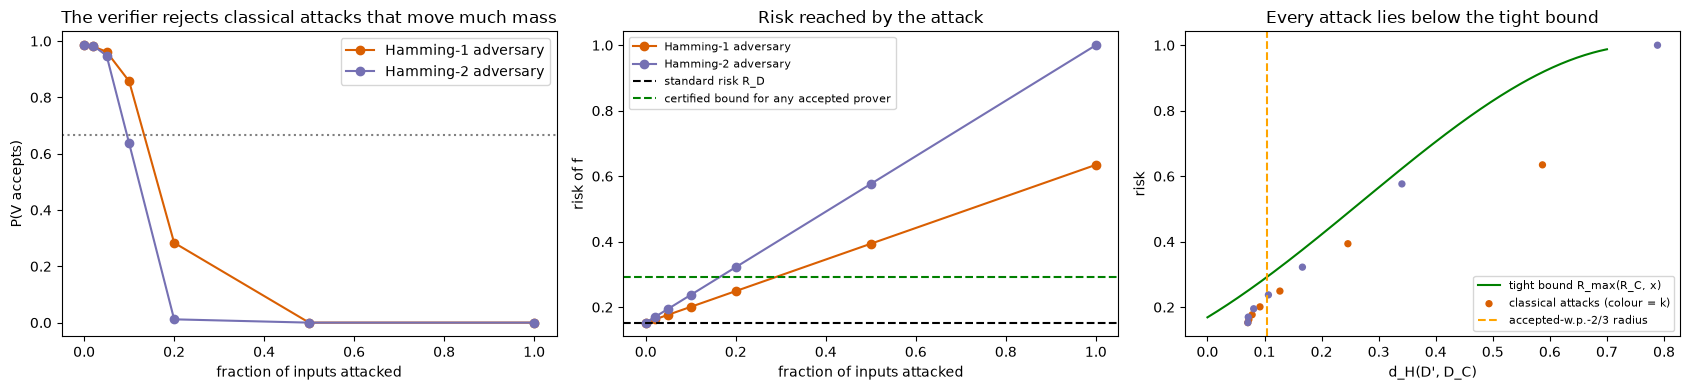

[V16] REPRODUCED: exact Hamming-1 adversary raises the risk from 0.153 to 0.635 and moves D by d_H = 0.58; the fully attacked stream is accepted w.p. 5.4e-63; only attacks on <= 10% of the inputs are accepted (risk gain bounded by the certificate). 'Exponentially larger' cannot be tested at n = 5
[V17] REPRODUCED: holds, and the shift term is computed exactly: accepted provers reach at most 0.293 (standard risk 0.153, model risk 0.169); explicit worst-case prover attains the bound (gap 0.0e+00), optimiser provers get within 1.0e-11, no classical attack exceeds it. With the paper's constant 10 the bound is 1.38 (vacuous at this eta)


In [30]:
# ---------------- classical attacks versus the verifier (V16) ----------------
rows = []
for k in (1, 2):
    for q in (0.0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0):
        Dk = pushforward(D_test, k, q); pc = p_out1(Dk, G, NQ)
        rows.append([k, q, hell(Dk, D_test), hell(Dk, D_C), pc, accept_prob(N_RUN, pc, ETA), float(Dk[err].sum())])
atk = pd.DataFrame(rows, columns=["Hamming radius k", "fraction q attacked", "d_H(D', D)", "d_H(D', D_C)", "P(out=1) circuit", "P(V accepts)", "risk of f under D'"])
print(atk.round(4).to_string(index=False))
q_acc = {k: max([r[1] for r in rows if r[0] == k and r[5] >= 2 / 3] + [0.0]) for k in (1, 2)}
print("largest attacked fraction still accepted w.p. >= 2/3:", q_acc)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, c in ((1, "#d95f02"), (2, "#7570b3")):
    s_ = atk[atk["Hamming radius k"] == k]
    ax[0].plot(s_["fraction q attacked"], s_["P(V accepts)"], "o-", c=c, label=f"Hamming-{k} adversary"); ax[1].plot(s_["fraction q attacked"], s_["risk of f under D'"], "o-", c=c, label=f"Hamming-{k} adversary")
ax[0].axhline(2 / 3, c="gray", ls=":"); ax[0].set_xlabel("fraction of inputs attacked"); ax[0].set_ylabel("P(V accepts)"); ax[0].set_title("The verifier rejects classical attacks that move much mass"); ax[0].legend()
ax[1].axhline(R_D, c="k", ls="--", label="standard risk R_D"); ax[1].axhline(float(tight_risk(R_C, x_ex)), c="g", ls="--", label="certified bound for any accepted prover"); ax[1].set_xlabel("fraction of inputs attacked"); ax[1].set_ylabel("risk of f"); ax[1].set_title("Risk reached by the attack"); ax[1].legend(fontsize=8)
xx = np.linspace(0, 0.7, 200)
ax[2].plot(xx, [tight_risk(R_C, x_) for x_ in xx], "g-", label="tight bound R_max(R_C, x)")
ax[2].scatter(atk["d_H(D', D_C)"], atk["risk of f under D'"], c=np.where(atk["Hamming radius k"] == 1, "#d95f02", "#7570b3"), s=18, label="classical attacks (colour = k)")
ax[2].axvline(x_ex, c="orange", ls="--", label="accepted-w.p.-2/3 radius"); ax[2].set_xlabel("d_H(D', D_C)"); ax[2].set_ylabel("risk"); ax[2].legend(fontsize=8); ax[2].set_title("Every attack lies below the tight bound")
plt.tight_layout(); plt.show()
viol_bound = int((atk["risk of f under D'"] > np.array([float(tight_risk(R_C, d_)) for d_ in atk["d_H(D', D_C)"]]) + 1e-9).sum())   # every D' lies below the tight bound for ITS OWN radius
rejected_full = bool((atk[atk["fraction q attacked"] == 1.0]["P(V accepts)"] < 0.5).all())
R1 = float(D_test[dist_err <= 1].sum())
full1 = atk[(atk["Hamming radius k"] == 1) & (atk["fraction q attacked"] == 1.0)]
dshift1 = float(full1["d_H(D', D)"].iloc[0]); pacc1 = float(full1["P(V accepts)"].iloc[0])
verdict("V16", "motivation: l_p-type (here Hamming) adversaries enlarge the risk and move D far in Hellinger distance, so V rejects them", "qualitative",
        f"exact Hamming-1 adversary raises the risk from {R_D:.3f} to {R1:.3f} and moves D by d_H = {dshift1:.2f}; the fully attacked stream is accepted w.p. {pacc1:.1e}; only attacks on <= {q_acc[1]:.0%} of the inputs are accepted (risk gain bounded by the certificate). 'Exponentially larger' cannot be tested at n = 5",
        "reproduced" if (R1 > R_D + 0.02 and rejected_full) else "not reached")
tight_ok = abs(DA_star[err].sum() - float(tight_risk(R_C, x_ex))) < 0.02 and gap_opt < 0.02 and (opt_df.iloc[:, 2] <= opt_df.iloc[:, 1] + 1e-7).all() and viol_bound == 0
verdict("V17", "headline: an accepted prover cannot push the risk beyond the standard risk plus a distribution-shift term (reduction of adversarial robustness to shift-robustness)", "R_{D_A}(f) ~ R_D(f) when d_H(D_A, D) = O(eta)",
        f"holds, and the shift term is computed exactly: accepted provers reach at most {float(tight_risk(R_C, x_ex)):.3f} (standard risk {R_D:.3f}, model risk {R_C:.3f}); explicit worst-case prover attains the bound (gap {abs(DA_star[err].sum() - float(tight_risk(R_C, x_ex))):.1e}), optimiser provers get within {gap_opt:.1e}, no classical attack exceeds it. With the paper's constant 10 the bound is {cert.iloc[0,1]:.2f} (vacuous at this eta)",
        "reproduced" if tight_ok else "not reached")

In [31]:
# ---------------- end to end: the risk measured on the samples V actually returns ----------------
rge = np.random.default_rng(SEED + 14); TE = max(500, MC_TRIALS // 8)
x_acc_k1 = q_acc[1]
scen = [("honest prover, |psi_D>", [(1.0, D_test)]),
        (f"Hamming-1 adversary on {x_acc_k1:.0%} of the inputs", [(1.0, pushforward(D_test, 1, x_acc_k1))]),
        ("strongest prover accepted w.p. 2/3 (worst-case state)", [(1.0, DA_star)]),
        ("Hamming-1 adversary on every input", [(1.0, pushforward(D_test, 1, 1.0))]),
        ("Hamming-1 adversary on 20% of the inputs", [(1.0, pushforward(D_test, 1, 0.2))])]
rows = []
for nm, prov in scen:
    accs = 0; risks = []
    for _ in range(TE):
        a_, S_, ph_, n1_ = run_protocol(prov, N_RUN, ETA, G, NQ, rge)
        if a_: accs += 1; risks.append(float(err[S_].mean()))
    rows.append([nm, accs / TE, accept_prob(N_RUN, p_out1(prov[0][1], G, NQ), ETA), np.mean(risks) if risks else np.nan, float(prov[0][1][err].sum())])
e2e = pd.DataFrame(rows, columns=["prover", "accept rate (MC)", "accept prob (exact)", "mean risk of f on the returned samples", "risk under the prover's distribution"])
print(f"{TE} protocol runs per prover, N = {N_RUN} rounds; certified bound for any prover accepted w.p. >= 2/3: {float(tight_risk(R_C, x_ex)):.4f}")
print(e2e.round(4).to_string(index=False))

5000 protocol runs per prover, N = 1082 rounds; certified bound for any prover accepted w.p. >= 2/3: 0.2933
                                               prover  accept rate (MC)  accept prob (exact)  mean risk of f on the returned samples  risk under the prover's distribution
                               honest prover, |psi_D>            0.9874               0.9853                                  0.1525                                0.1527
             Hamming-1 adversary on 10% of the inputs            0.8532               0.8574                                  0.2012                                0.2009
strongest prover accepted w.p. 2/3 (worst-case state)            0.6706               0.6667                                  0.2928                                0.2933
                   Hamming-1 adversary on every input            0.0000               0.0000                                     NaN                                0.6346
             Hamming-1 adversary on 2

## 11. Side by side: classical certificates versus the quantum-model certificate, on the same data

                                               defence                  threat covered                              kind of number   risk
                                         f, no defence                            none                                           - 0.1527
                                         f, no defence any Hamming-1 adversary (exact)                                       exact 0.6346
                                         f, no defence any Hamming-2 adversary (exact)                                       exact 1.0000
               bit-flip randomised smoothing, rho=0.05                Hamming radius 1                       certified upper bound 0.6346
               bit-flip randomised smoothing, rho=0.05                Hamming radius 2                       certified upper bound 1.0000
               bit-flip randomised smoothing, rho=0.05                Hamming radius 2 exact worst case of the smoothed classifier 1.0000
quantum verifier (this paper), pap

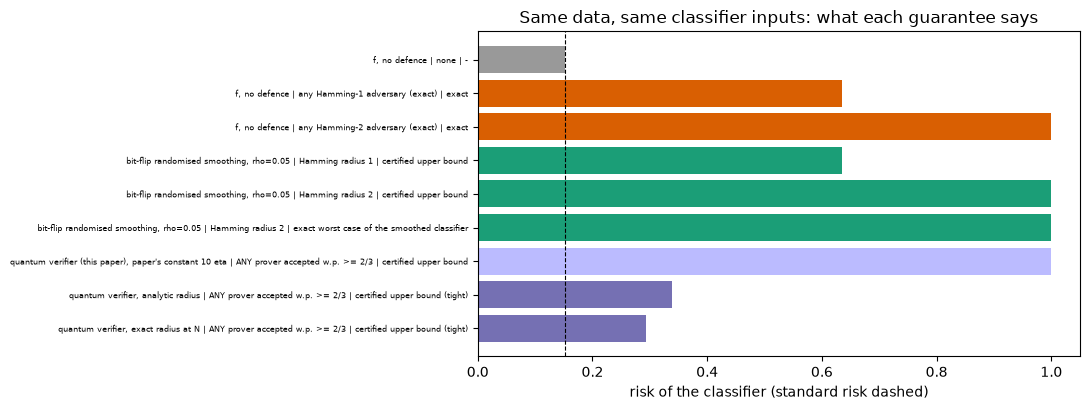

In [32]:
rho_best = max(SMOOTH_RHOS, key=lambda r: RS[r]["cert"][1])
cmp_rows = [
    ["f, no defence", "none", "-", R_D],
    ["f, no defence", "any Hamming-1 adversary (exact)", "exact", 1 - base_adv_acc[1]],
    ["f, no defence", "any Hamming-2 adversary (exact)", "exact", 1 - base_adv_acc[2]],
    [f"bit-flip randomised smoothing, rho={rho_best}", "Hamming radius 1", "certified upper bound", 1 - RS[rho_best]["cert"][1]],
    [f"bit-flip randomised smoothing, rho={rho_best}", "Hamming radius 2", "certified upper bound", 1 - RS[rho_best]["cert"][2]],
    [f"bit-flip randomised smoothing, rho={rho_best}", "Hamming radius 2", "exact worst case of the smoothed classifier", 1 - RS[rho_best]["adv_acc"][2]],
    ["quantum verifier (this paper), paper's constant 10 eta", "ANY prover accepted w.p. >= 2/3", "certified upper bound", min(1.0, float(cert.iloc[0, 1]))],
    ["quantum verifier, analytic radius", "ANY prover accepted w.p. >= 2/3", "certified upper bound (tight)", float(tight_risk(R_C, x_an))],
    ["quantum verifier, exact radius at N", "ANY prover accepted w.p. >= 2/3", "certified upper bound (tight)", float(tight_risk(R_C, x_ex))],
]
cmp_df = pd.DataFrame(cmp_rows, columns=["defence", "threat covered", "kind of number", "risk"])
print(cmp_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
fig, ax = plt.subplots(figsize=(11, 4.2))
cl = ["#999999", "#d95f02", "#d95f02", "#1b9e77", "#1b9e77", "#1b9e77", "#bbbbff", "#7570b3", "#7570b3"]
ax.barh(range(len(cmp_df)), cmp_df["risk"], color=cl); ax.set_yticks(range(len(cmp_df)))
ax.set_yticklabels([f"{a} | {b} | {k}" for a, b, k in zip(cmp_df["defence"], cmp_df["threat covered"], cmp_df["kind of number"])], fontsize=6); ax.invert_yaxis(); ax.axvline(R_D, c="k", ls="--", lw=.8)
ax.set_xlabel("risk of the classifier (standard risk dashed)"); ax.set_title("Same data, same classifier inputs: what each guarantee says")
plt.tight_layout(); plt.show()

## 12. Paper versus this notebook: per-claim verdicts

Verdict rule: **reproduced** = the statement holds in the numerical test (identities within 1e-9, statistical quantities within 0.02, scaling exponents within 0.2); **not reached** = the test contradicts the statement as written;
**exceeded** = the statement holds with a better constant than written (reported inside the measurement text); **cannot be checked** = needs a hardness assumption or a resource beyond a CPU. The paper contains no accuracy, F1 or timing numbers, so there is no numeric table to compare with.

  V1 | REPRODUCED        | Section 2: d_H^2 <= TV <= sqrt(2) d_H and 1-d_H^2 = sum sqrt(PQ)
       paper: stated (standard)
       here : 20000 random pairs, 0 violations, identity error 1.7e-16

  V2 | REPRODUCED        | Lemma 1 / Corollary 1: P(out=1) = (1+(1-d_H^2)^2)/2
       paper: exact identity
       here : max error 8.6e-14 over 1355 circuits (non-negative C); signed C violates Corollary 1 by 0.143 on average (Lemma 1 form still exact)

  V3 | REPRODUCED        | Fact 1: P[|mean - p| > eps] <= 2 exp(-eps^2 k/2)
       paper: stated (Chernoff-Hoeffding)
       here : 100 exact binomial tails, 0 violations (max ratio 0.43)

  V4 | REPRODUCED        | Lemma 2: n_0, n_1 > N/4 with probability >= 1-delta for N = Omega(log 1/delta)
       paper: N = Omega(log(1/delta))
       here : exact failure probability <= delta at N = ceil(32 ln(4/delta)) for all tested delta (true minimum N is 9x smaller at delta = 0.05)

  V5 | REPRODUCED        | Theorem 2 completeness: accepted w.p. 1-del

VERDICT COUNTS: {'reproduced': 14, 'cannot be checked': 3, 'not reached': 2} | total claims 19 | elapsed 3065s


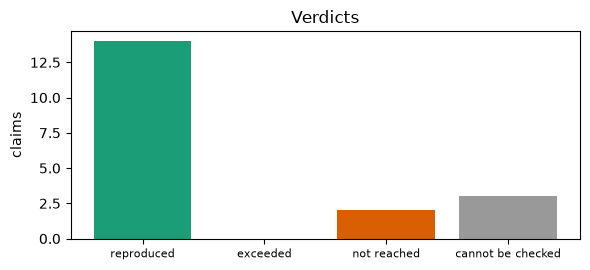

In [33]:
vt = pd.DataFrame(VERDICTS)
pd.set_option("display.max_colwidth", 400, "display.width", 250)
for _, r in vt.iterrows():
    print(f"{r['id']:>4} | {r['verdict'].upper():<17} | {r['claim']}\n       paper: {r['paper']}\n       here : {r['notebook']}\n")
counts = vt["verdict"].value_counts().to_dict()
print("VERDICT COUNTS:", counts, f"| total claims {len(vt)} | elapsed {time.time()-T0:.0f}s")
fig, ax = plt.subplots(figsize=(6, 2.8)); order = ["reproduced", "exceeded", "not reached", "cannot be checked"]
ax.bar(order, [counts.get(k, 0) for k in order], color=["#1b9e77", "#66a61e", "#d95f02", "#999999"]); ax.set_ylabel("claims"); ax.set_title("Verdicts")
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()

### Summary of the executed run (`FAST_MODE = False`)

* **Verdicts (19 items):** 14 reproduced, 2 not reached, 3 cannot be checked. *Not reached*: the proof step `d_H >= sqrt(2) TV` of Lemma 3 (false for every random pair; the lemma's conclusion survives and even improves to a linear `10 eta` bound) and the linear-in-`epsilon` clock-probability bound of Lemma 4 (the exact worst case grows like `sqrt(epsilon T')`: 0.247 relative deviation at `epsilon = 0.002` against the claimed 0.010).
  *Cannot be checked*: the garbled second bullet of Lemma 4, Theorem 5 as a whole, and the classical-verifier Theorems 6 to 9.
* **Circuit identities.** The comparison circuit reproduces Lemma 1 / Corollary 1 to about `1e-13` on 1355 circuits (random 7-qubit circuits and the trained 11-qubit circuit with real-data states); a signed `C` breaks Corollary 1 by 0.14 on average, which is why the trained `C` carries a diagonal sign gate.
* **Protocol.** With the trained 5-qubit generative circuit, `eta_test = d_H(D_test, D_C) = 0.071` (the sampling-noise floor of the 1984 test images is 0.069), the protocol parameter is `eta = 0.08` and `N = 1082` rounds give completeness 0.985 (Monte-Carlo 0.986). The exact soundness radius is `1.31 eta` (analytic `1.74 eta`), against the paper's `10 eta`. The number of rounds scales like `eta^-2.15` (paper: `eta^-2`).
* **Risk.** Standard risk of the SVM `R_D = 0.153`. The exact Hamming-1 adversary reaches 0.635 and Hamming-2 reaches 1.0; bit-flip randomised smoothing certifies only 36.5 percent accuracy at radius 1 for flip probability up to 0.10 (22 percent at 0.20; the undefended classifier's exact radius-1 accuracy is also 36.5 percent) and nothing at radius 2.
  Any prover accepted with probability at least 2/3 by the quantum verifier is held to risk at most **0.293** (exact radius, tight closed form); an explicit worst-case prover attains it and optimiser provers never exceed it. With the paper's constant `10 eta` the implied bound is 1.38 (no information) at this `eta`.
* **Where it breaks.** An adversary that attacks only 10 percent of the inputs with the Hamming-1 attack is still accepted (risk 0.20); attacking 20 percent or more is rejected with probability above 0.7, and attacking all inputs is accepted with probability below `1e-60`.

## 13. Reading the paper critically

* **What was verified.** The core mechanism is correct and the circuit does exactly what Lemma 1 says: `P(out=1) = (1 + |<psi_DA|psi_DC>|^2)/2`, to machine precision, on random 7-qubit circuits and on the trained 11-qubit circuit with real-data states. The i.i.d. protocol (Theorem 2) is complete and sound with constants much better than the written ones: the exact soundness radius is a small multiple of `eta` (analytically `sqrt(3) eta` with the paper's own estimation slack), not `10 eta`.
* **Non-negative amplitudes are essential and not stated.** The identity `P = f(d_H)` needs `|psi_DC> = sum sqrt(D_C(x)) |x>` with non-negative amplitudes. A generic trained circuit has signed amplitudes; then an *honest* prover is accepted with lower probability than the paper's analysis assumes (Corollary 1 over-estimates). Here this was repaired with one diagonal +-1 gate. In practice the verifier must know the phases of `C`'s output; this is an extra requirement on the generative model.
* **Sample complexity.** Fact 1 (additive error `eta^2`) alone would force `N ~ eta^-4`. The stated `N = O(eta^-2 log(1/delta))` is nevertheless right, because the honest success probability is `1 - O(eta^2)` and the variance is `O(eta^2)` (a relative Chernoff bound); the exact binomial computation shows the exponent `-2`. The proof as written does not show this.
* **Lemma 3 / Theorems 3 and 4: the `eta^{1/4}` is an artefact.** The proof of Lemma 3 uses `d_H >= sqrt(2) TV`, which is the wrong direction (Section 2 has `TV <= sqrt(2) d_H`). The conclusion survives, and the result can be strengthened to a *linear* bound `d_H(mixture, D_C) <= 10 eta` because `f(x) <= 1 - x^2/2` and the squared Hellinger distance is jointly convex. So the non-i.i.d. and mixed-state provers are no more dangerous than the i.i.d. ones, up to constants.
* **Lemma 4 is not true as stated.** With energy budget `epsilon/T'` the clock probabilities can deviate from `1/(T'+1)` by a relative amount that grows like `sqrt(epsilon T')`, not `5 epsilon`: the cheapest way to lower the energy of a path Hamiltonian is a smooth profile along the clock, and a smooth profile moves probability between the clock positions at first order in the amplitude. Corollary 2 (`7 eta` for budget `eta^2/T'^3`) is true with room to spare, which is the version the protocol needs, so Theorem 5 is not in danger, but the intermediate lemma needs a different statement.
* **Constants matter for use.** With the paper's `10 eta` the implied bound on the risk of an accepted prover is above 1 (1.38) at the `eta = 0.08` that the 5-qubit generative circuit reaches here. The *tight* closed-form certificate is informative (it is computed above), but it is a statement about `D_C(E)` and the Hellinger radius, i.e. about how well the generative model fits, not about the classifier alone.
* **The model, not the maths, is the limitation.** The adversary only receives quantum samples and the verifier needs a quantum computer (Theorem 2), a constant-size quantum computer plus `N ~ 1e10` rounds (Theorem 5) or a cryptographic assumption (Theorems 6 to 9). The guarantee is also about *distributions*, not individual inputs: a prover that replaces each input `x` by an unrelated `x'` drawn from `D` is never detected (the paper says so). Randomised smoothing certifies each input against a fixed perturbation set; the quantum protocol certifies the stream against any change that keeps it Hellinger-close to the data distribution. They answer different questions and the table above should not be read as a ranking.
* **What cannot be tested here.** The classical-verifier theorems (hardness assumption), the 5-locality of the unary-clock Hamiltonian, and anything about real quantum hardware.

## 14. Exercises

1. **Phases.** Replace the sign gate on `C` by nothing (use the raw circuit) and re-run Sections 5 and 6. By how much does the honest acceptance probability drop, and what `N` restores completeness?
2. **A better `C`.** Increase `QCBM_REPS` (try 6 and 8) and `THRESH_PER_PC` (3 gives `n = 7`). How does `eta` fall, and how does the certified risk of Section 10 follow? What is the noise floor `d_H(D_train, D_test)` as the number of strings grows?
3. **Another classifier.** Replace the SVM by a decision tree of depth 1 and by a random forest on the same 4 bits. How do `R_D(f)`, the Hamming-ball risk and the quantum certificate change? Which of the three numbers does the choice of `f` influence, and why is the quantum certificate expressed through `D_C(E)`?
4. **Tighten Lemma 4.** Using the extremal-state code of Section 8, find the budget exponent `a` such that the claim `(T'+1)|P - 1/(T'+1)| <= 5 epsilon` holds when `<H_G> <= epsilon^a / T'^b`. Does a pair `(a, b)` exist for all `epsilon`?
5. **Another threat model.** Implement an adversary that may change the *label bit* too (a poisoning-style prover) or that attacks a binary-coded (instead of thermometer-coded) quantisation of the PCA coordinates. Which of the guarantees of Section 11 still apply, and which do not?